In [1]:
import sccoda
import scanpy as sc
import pandas as pd
import numpy as np

from sccoda.util import cell_composition_data as dat
from sccoda.util import data_visualization as viz
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import gc
import plotly.graph_objects as go
import matplotlib.colors as mcolors

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

In [2]:
Heart = sc.read_h5ad("/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/Heart_atlas_TB_submission.h5ad")

In [3]:
Heart = Heart.raw.to_adata()

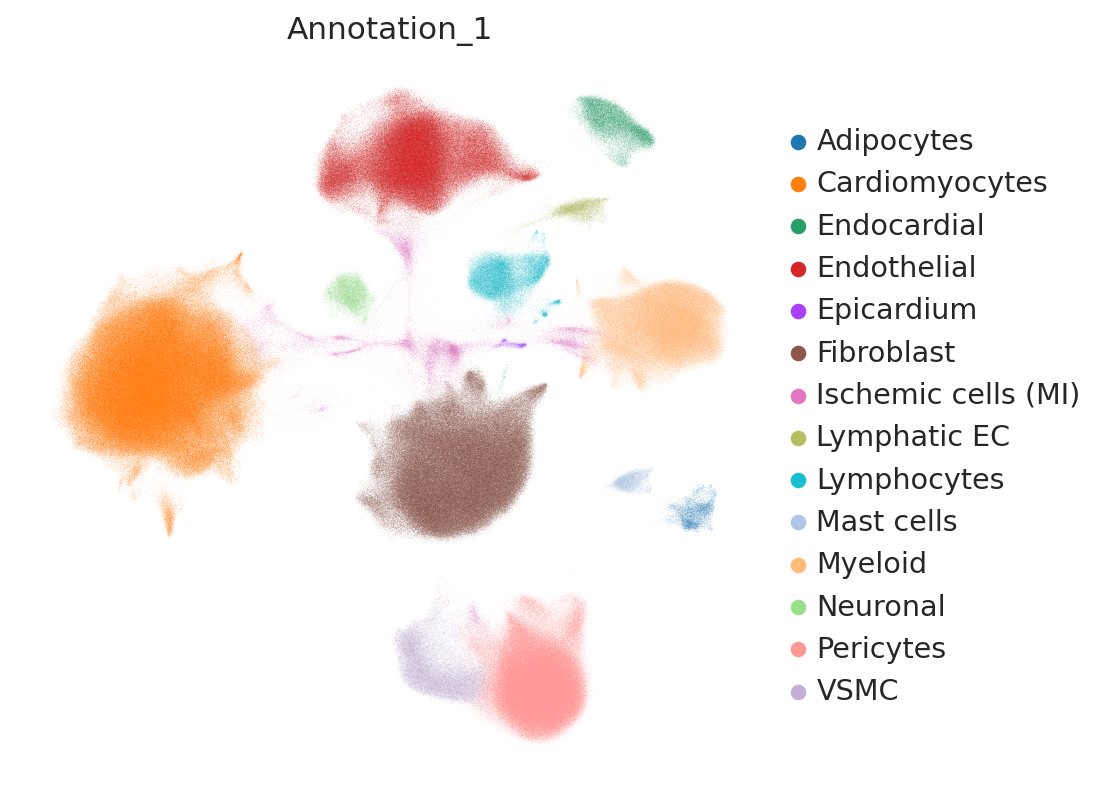

In [4]:
sc.set_figure_params(scanpy=True, dpi=8000, dpi_save=80000)
sc.set_figure_params(figsize=(6, 6))
sc.pl.umap(
    Heart,
    color=["Annotation_1"],
    frameon=False, save="_UMAP_Main_Cell_Types.pdf")

In [5]:
Heart = Heart[~(Heart.obs["Subclustering"].isin(['Discard OR LINGO1 cardiomyocytes #1', 'Discard', 'Fibroblast (APOD/E)', 'Cardiomyocytes (LINGO1)']))]
Heart = Heart[~(Heart.obs["Patient_Cluster"].isin(['CTRL_3']))]

In [6]:
gc.collect()

5460

/rwthfs/rz/cluster/home/uv525372/miniforge3/envs/sc_pertpy/lib/python3.10/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


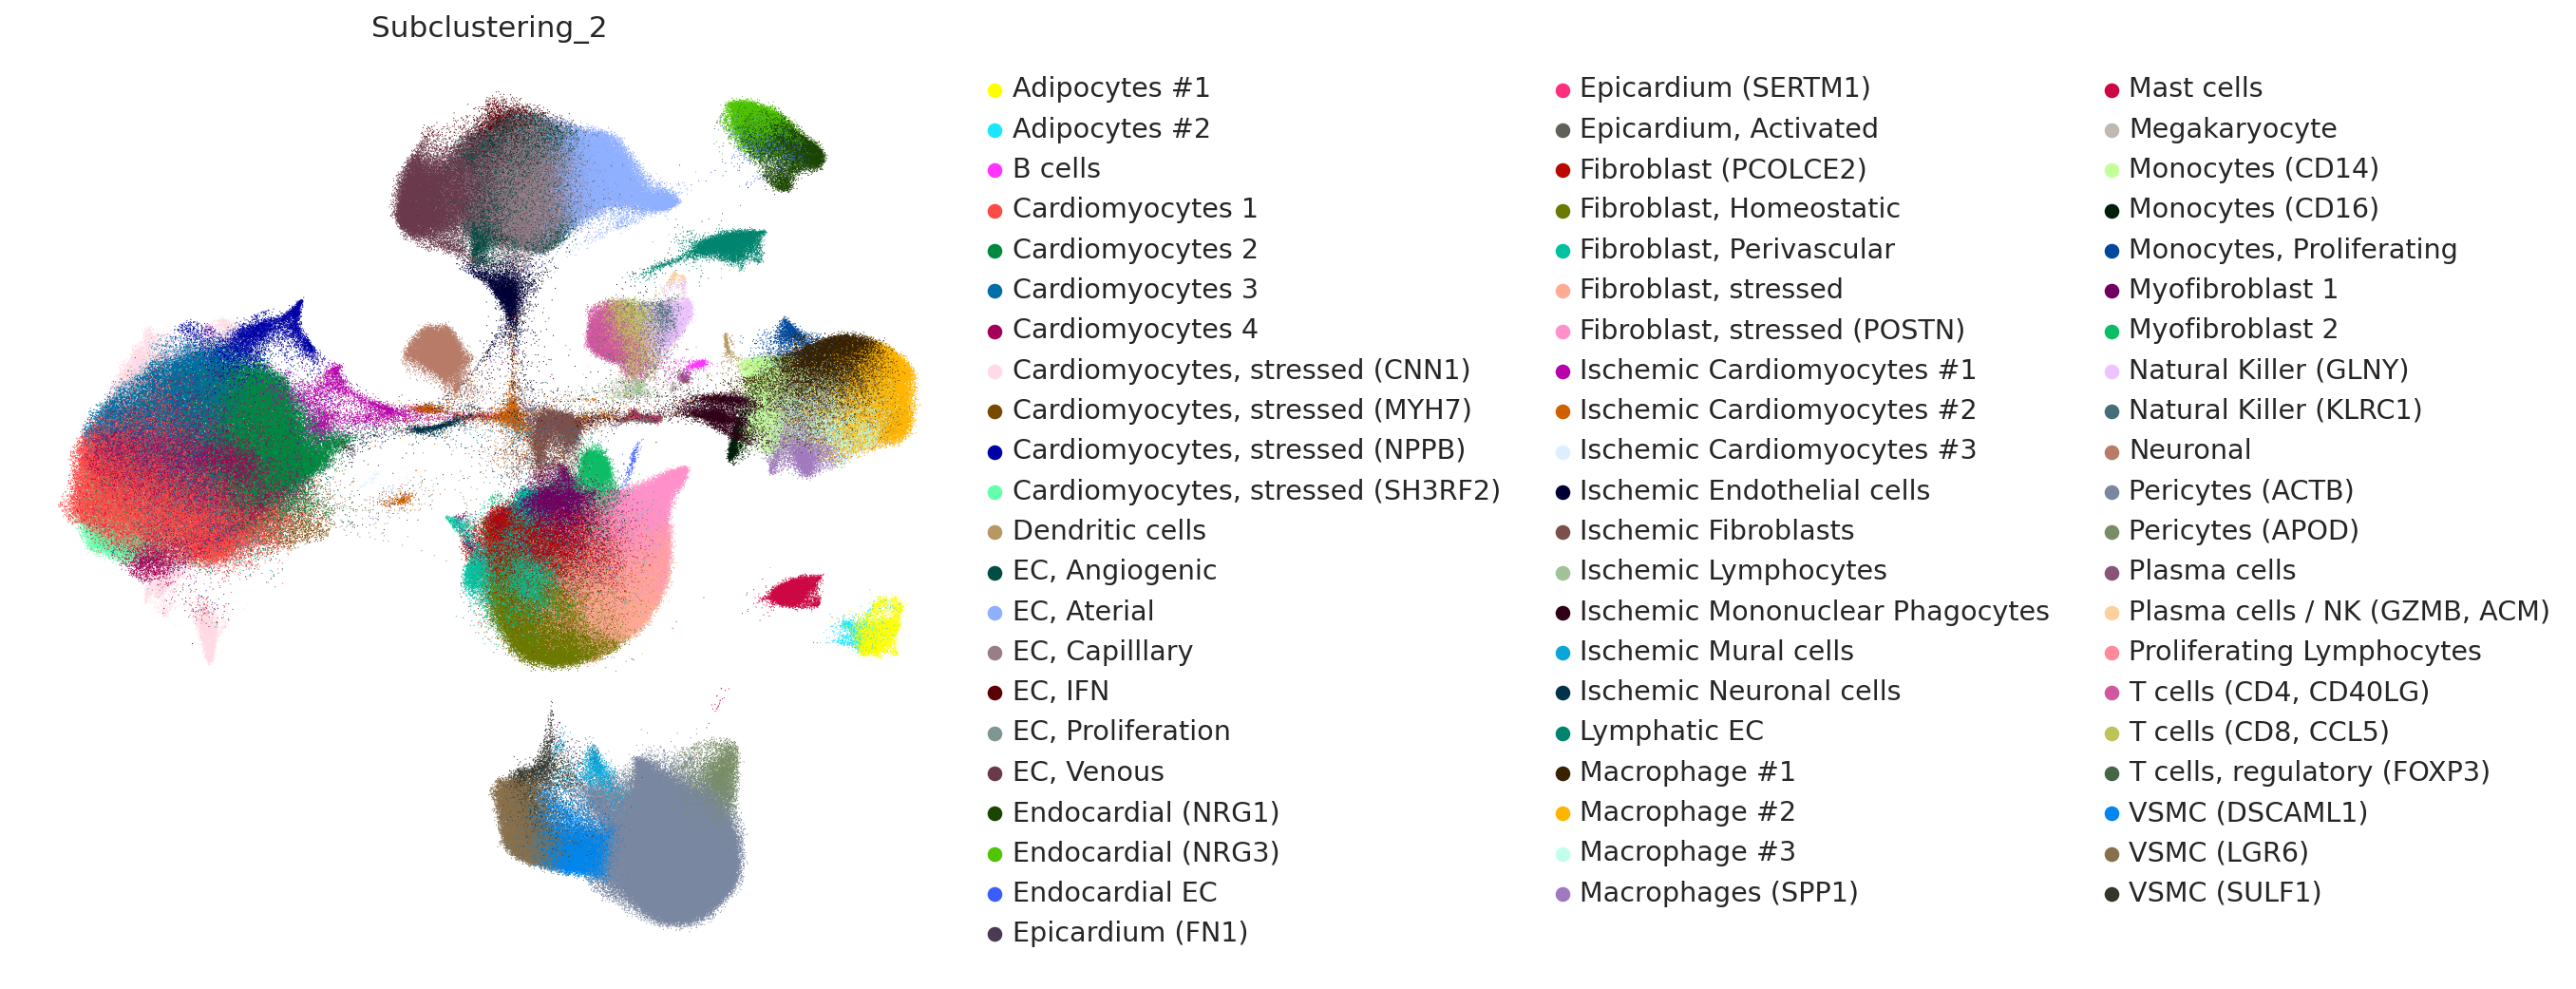

In [7]:
sc.set_figure_params(scanpy=True, dpi=8000, dpi_save=80000)
sc.set_figure_params(figsize=(8, 8))
sc.pl.umap(
    Heart, size=1, frameon=False,
    color=["Subclustering_2"])

Pericytes


<Figure size 480x400 with 0 Axes>

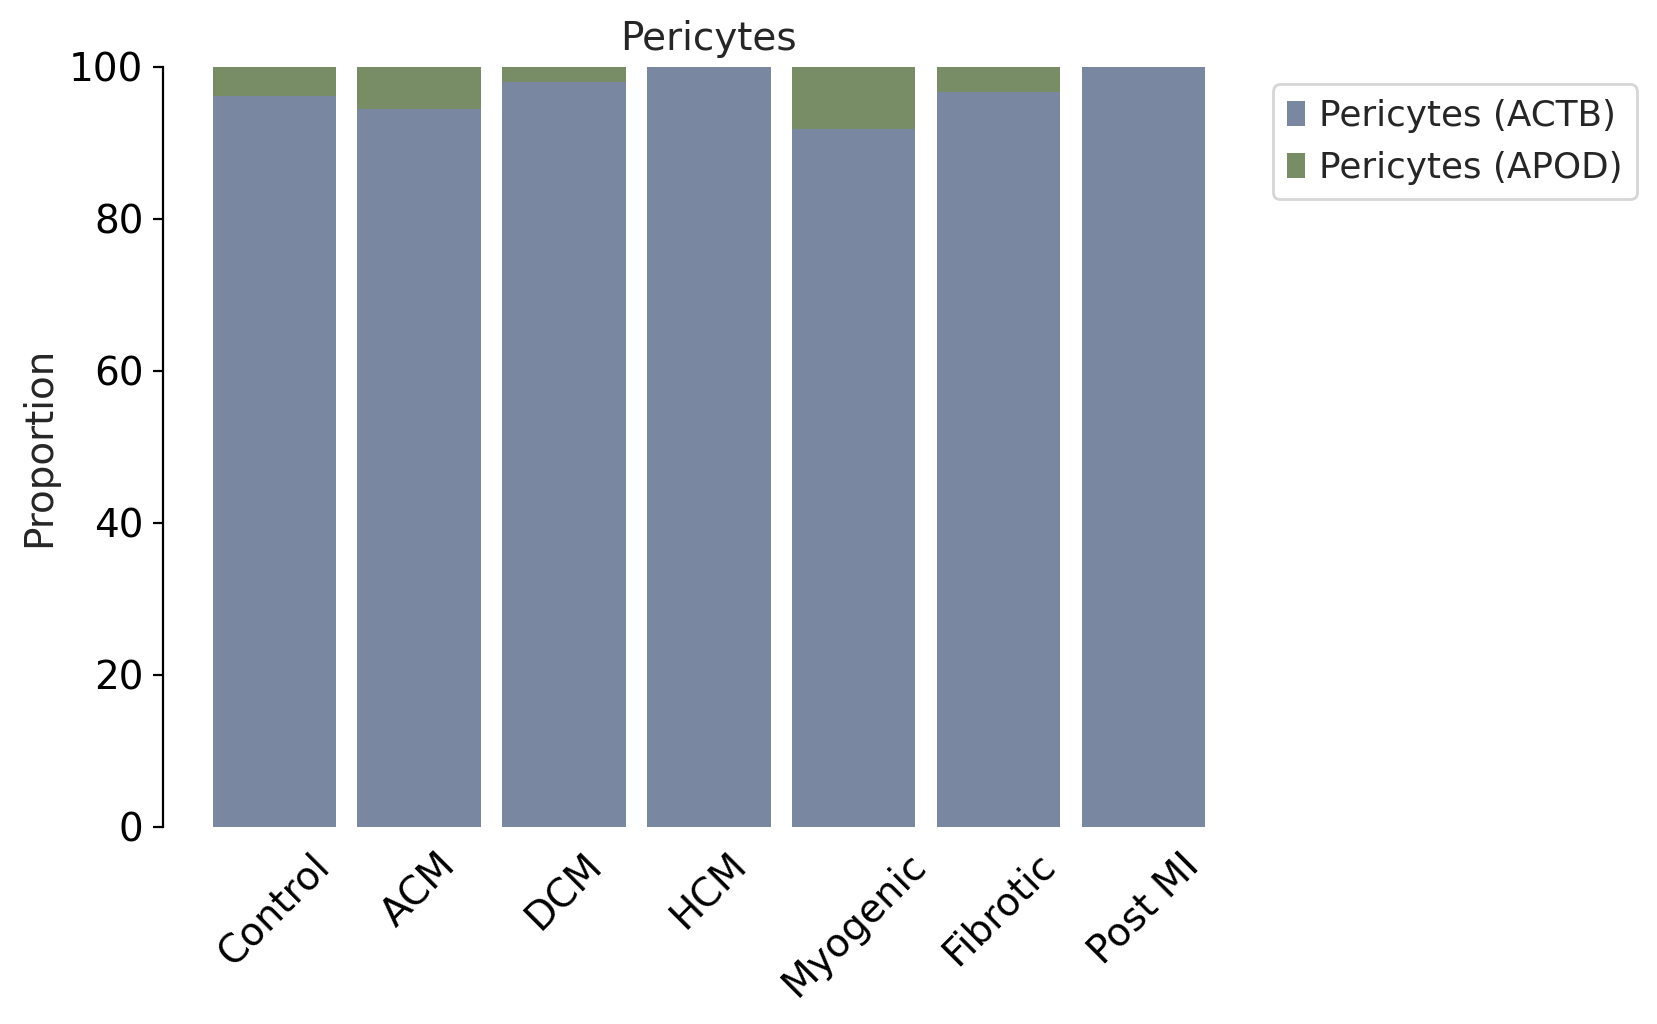

Cardiomyocytes


<Figure size 480x400 with 0 Axes>

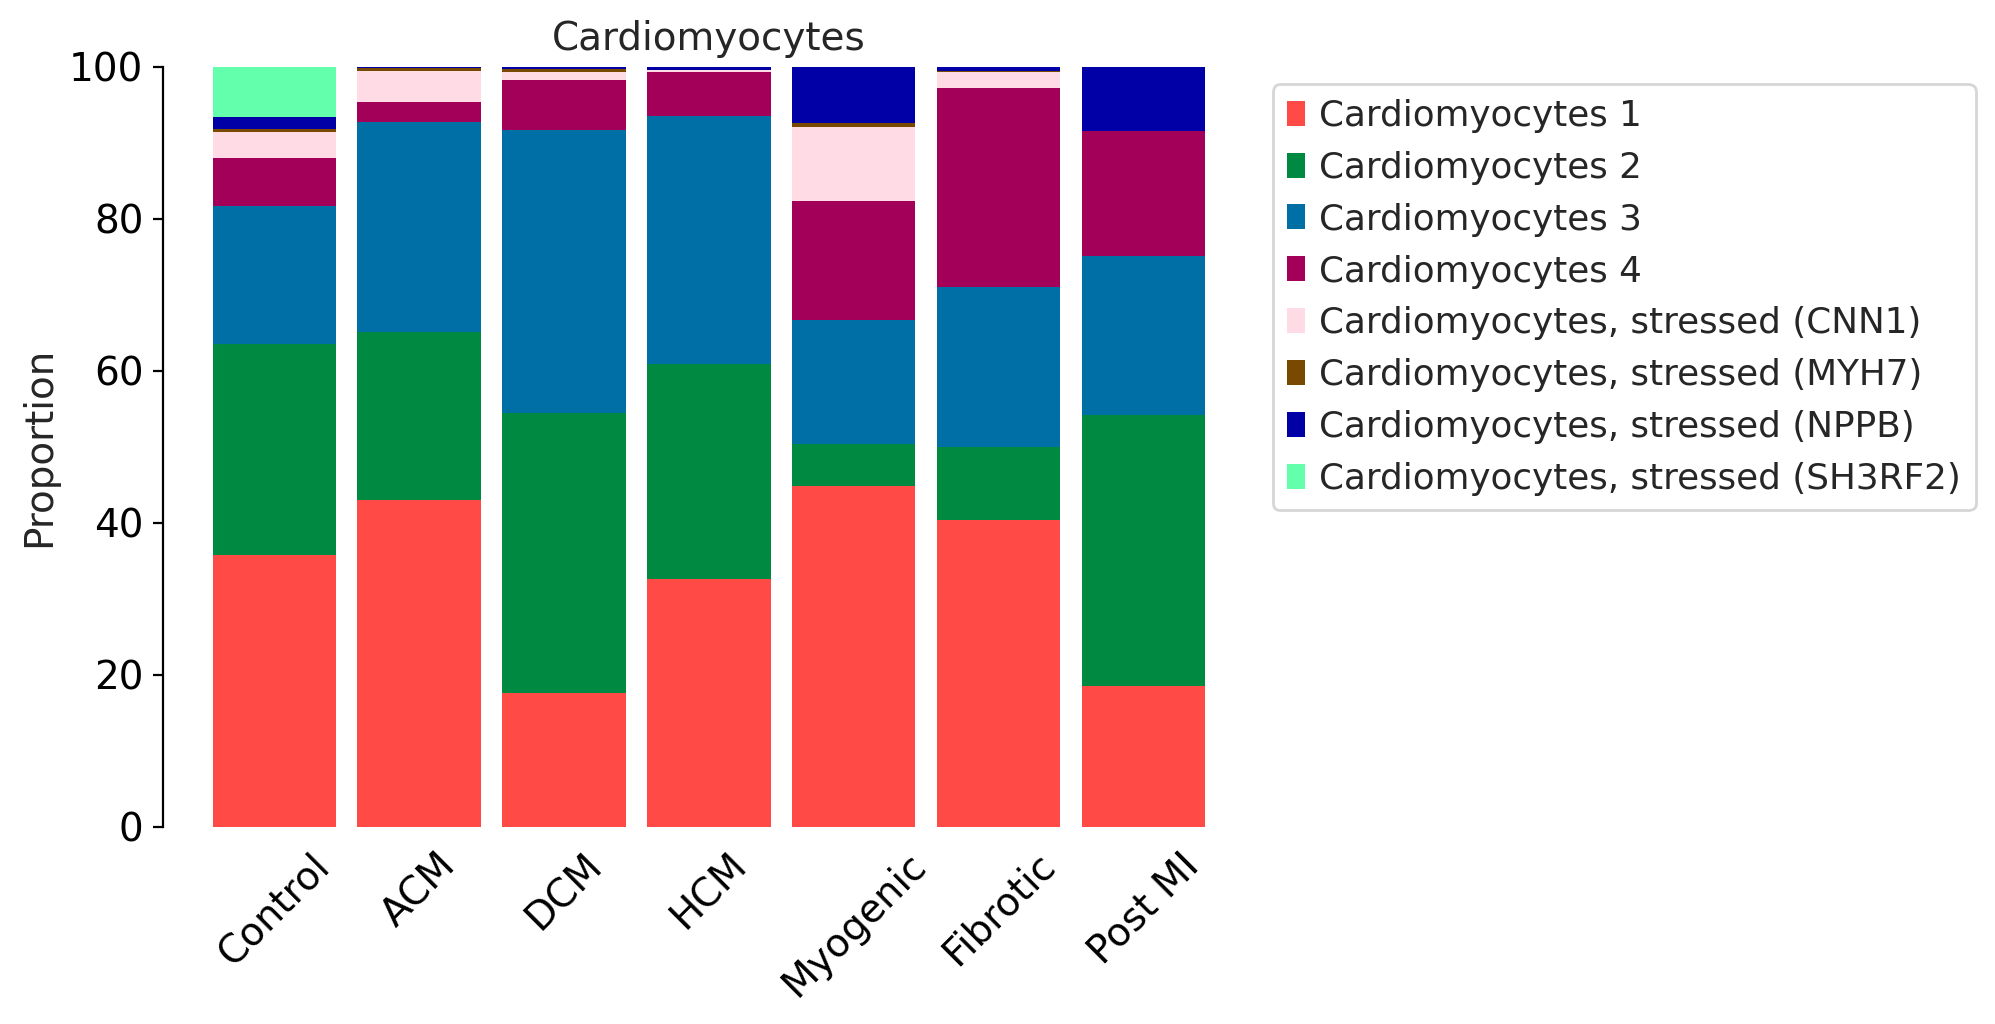

Lymphatic EC


<Figure size 480x400 with 0 Axes>

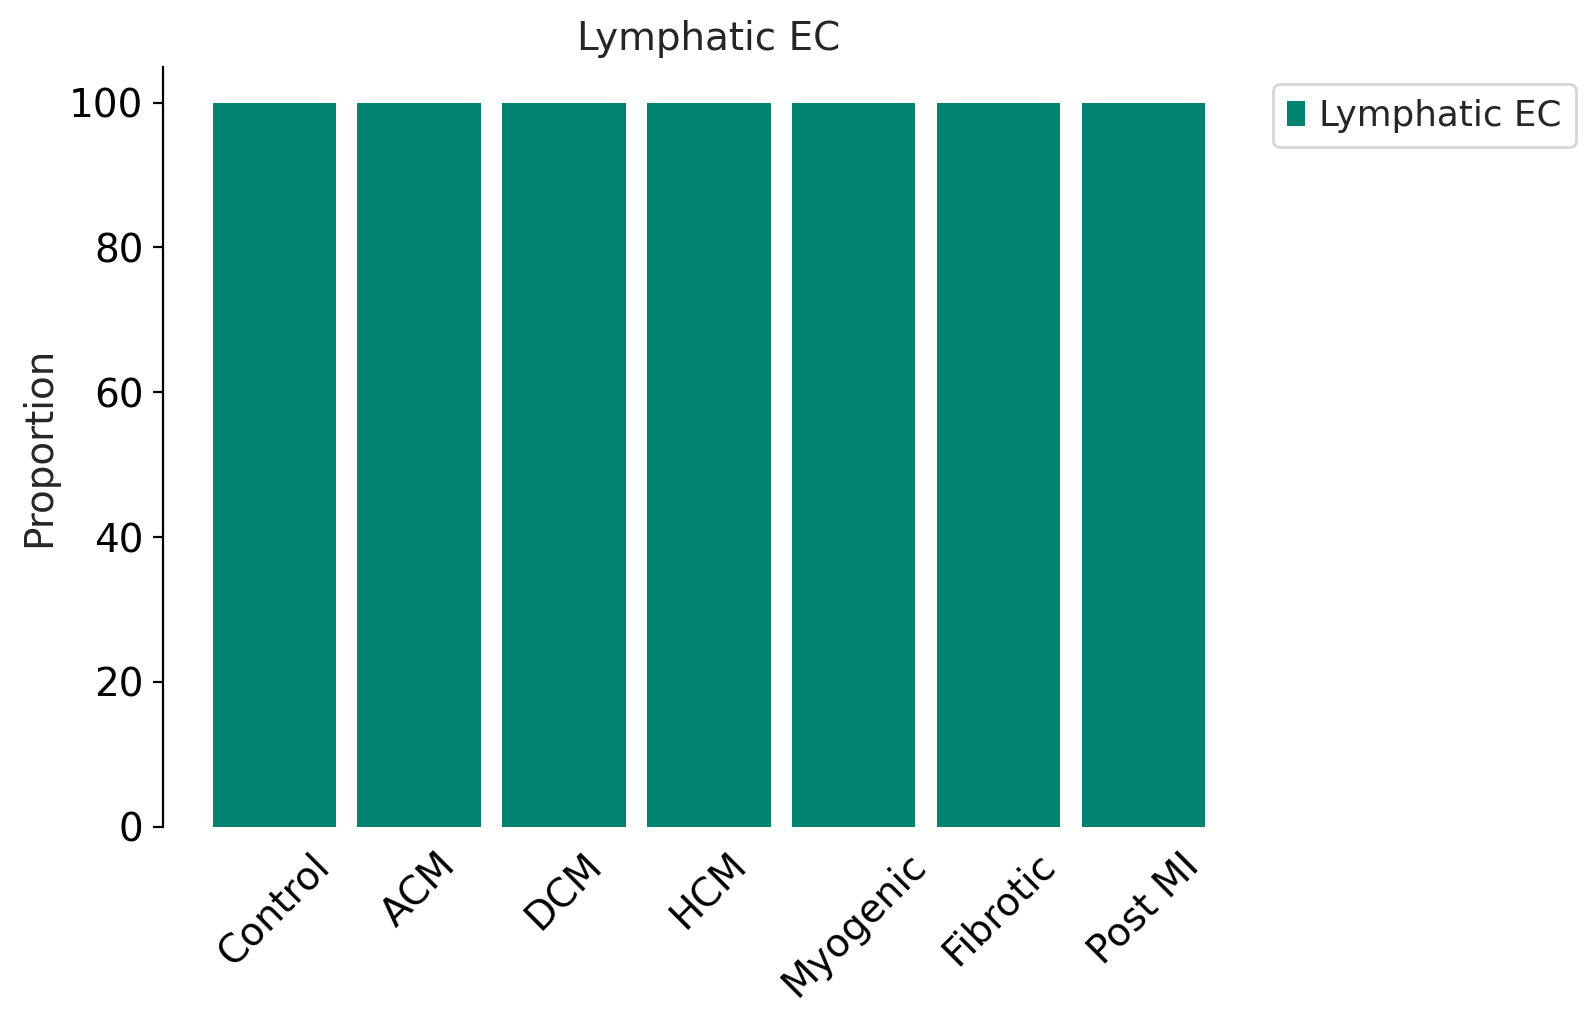

Fibroblast


<Figure size 480x400 with 0 Axes>

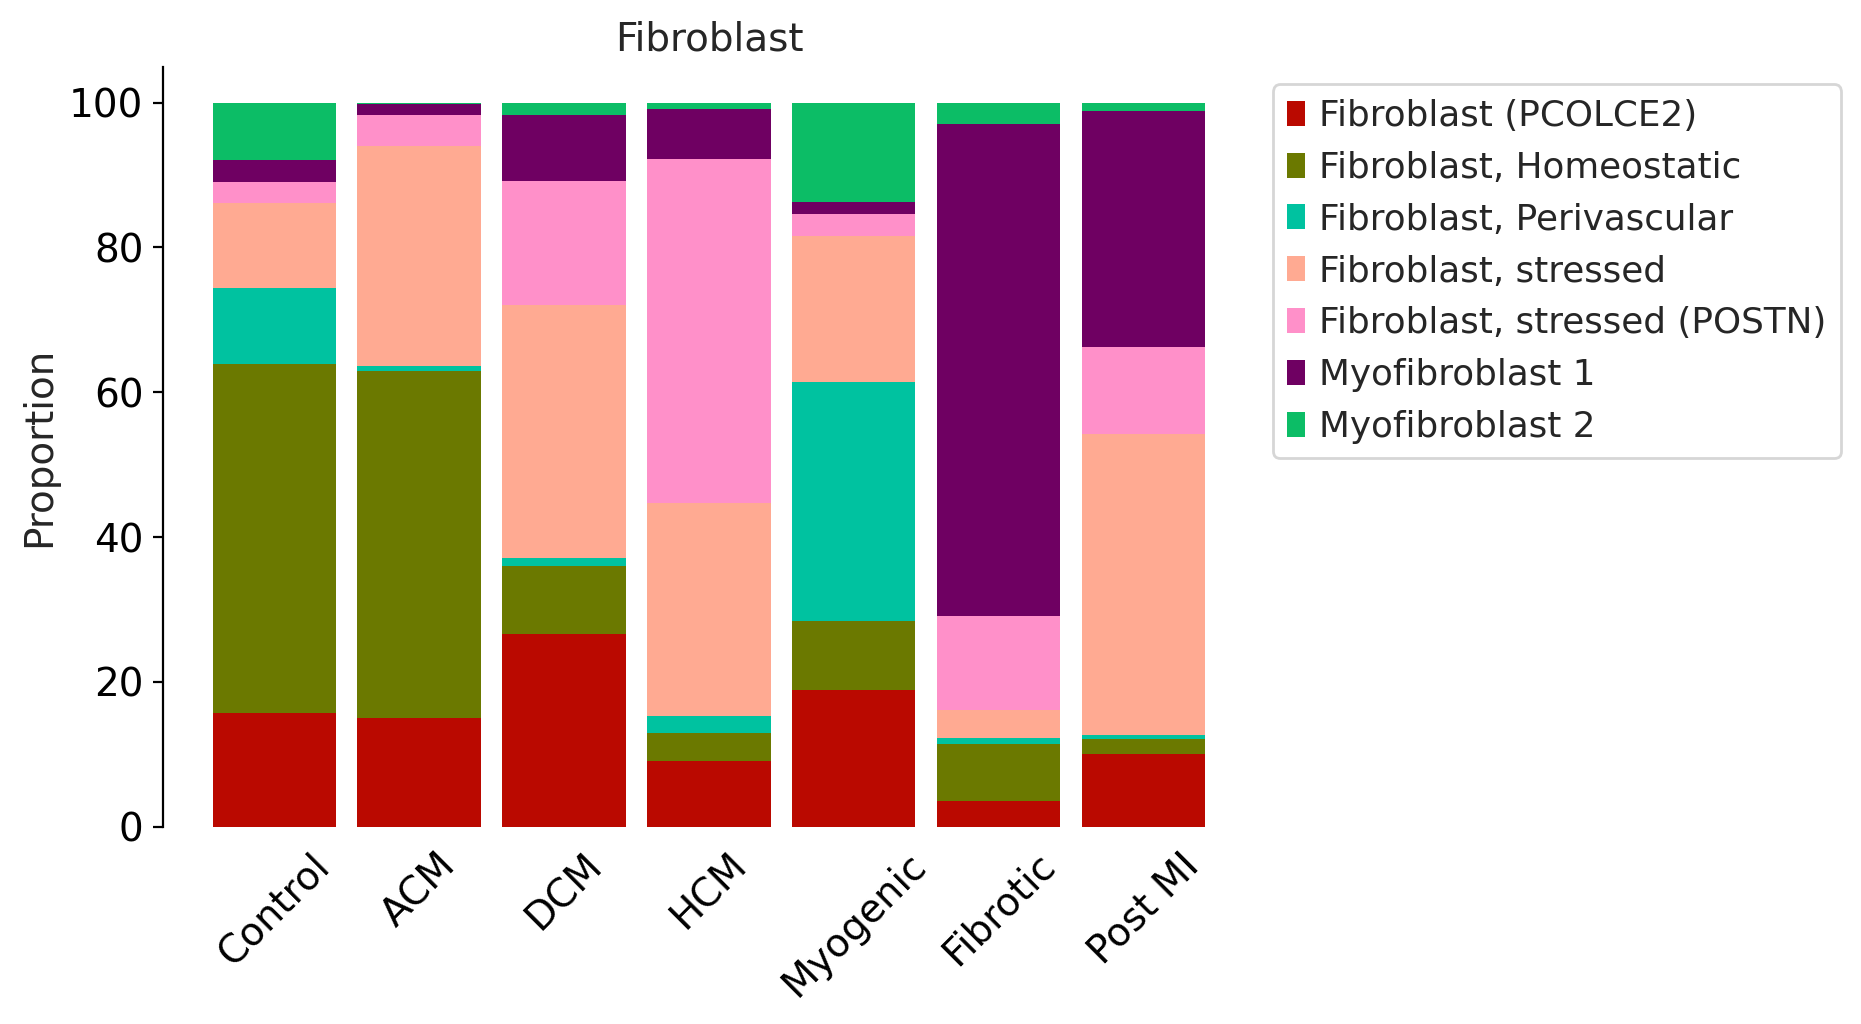

Lymphocytes


<Figure size 480x400 with 0 Axes>

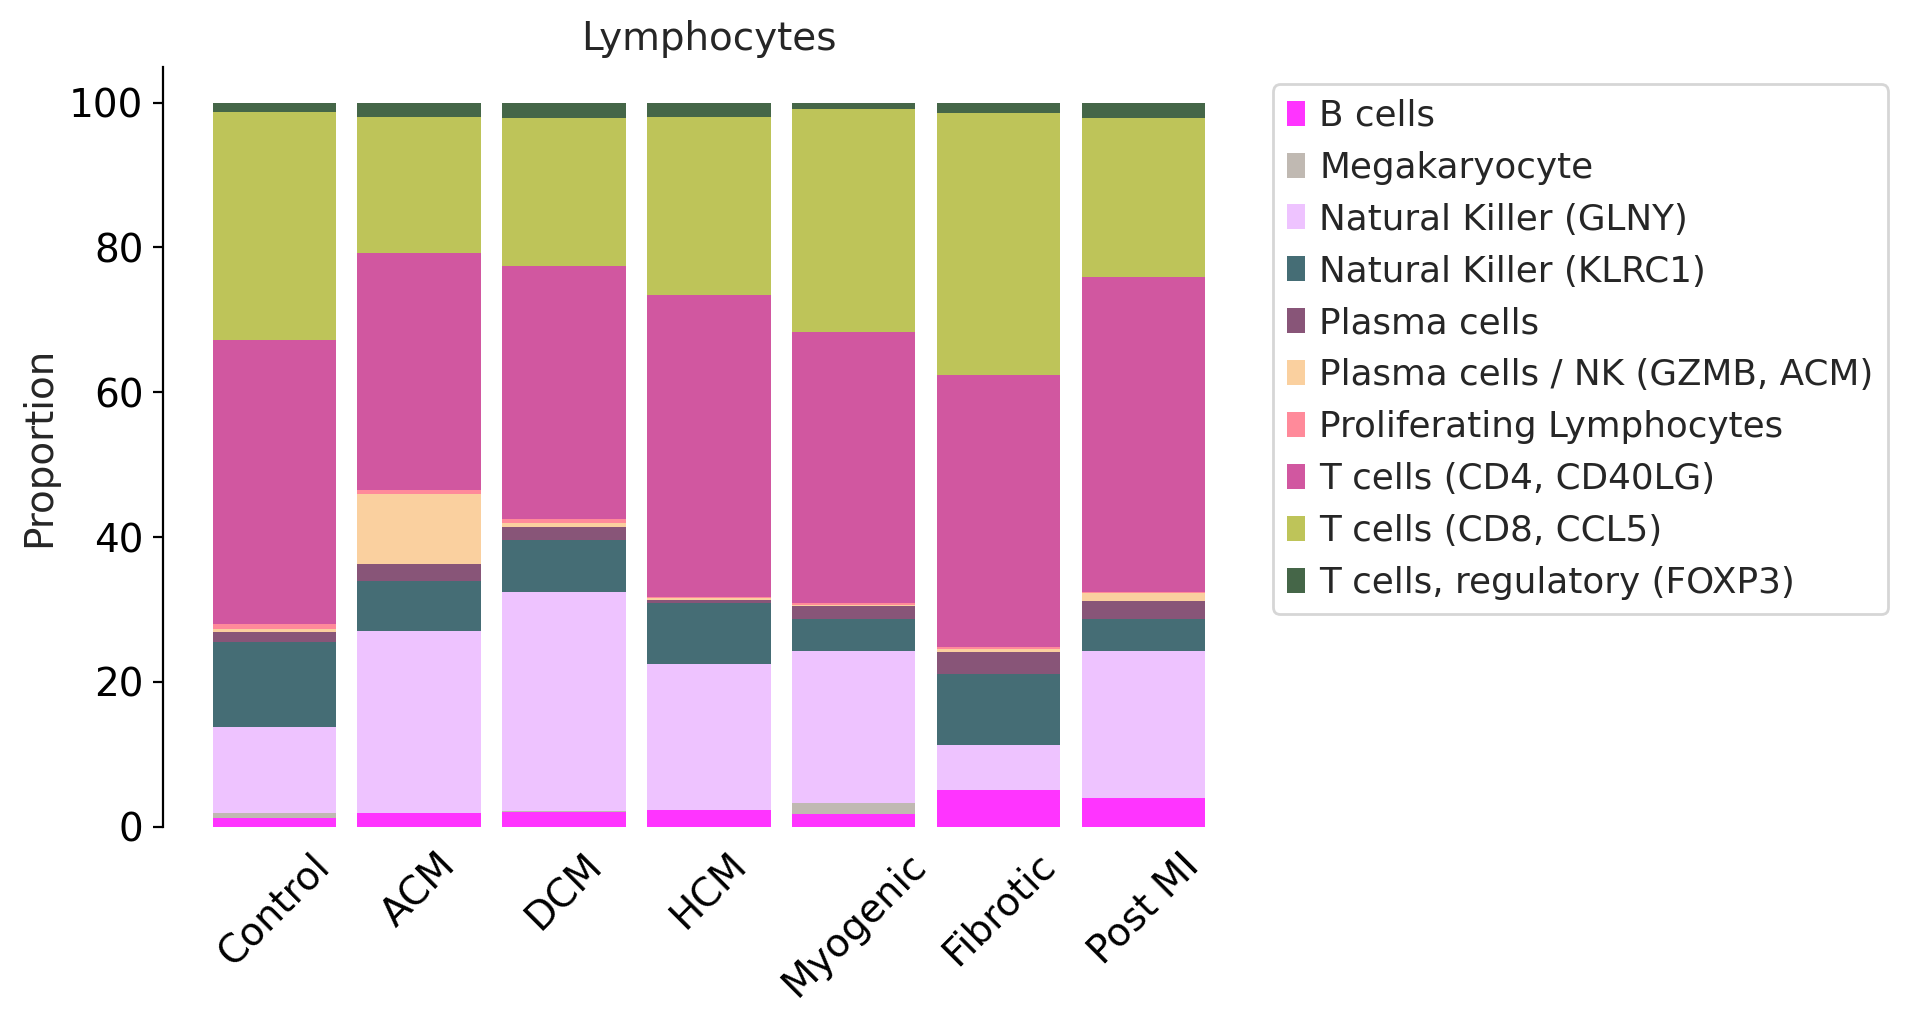

Endothelial


<Figure size 480x400 with 0 Axes>

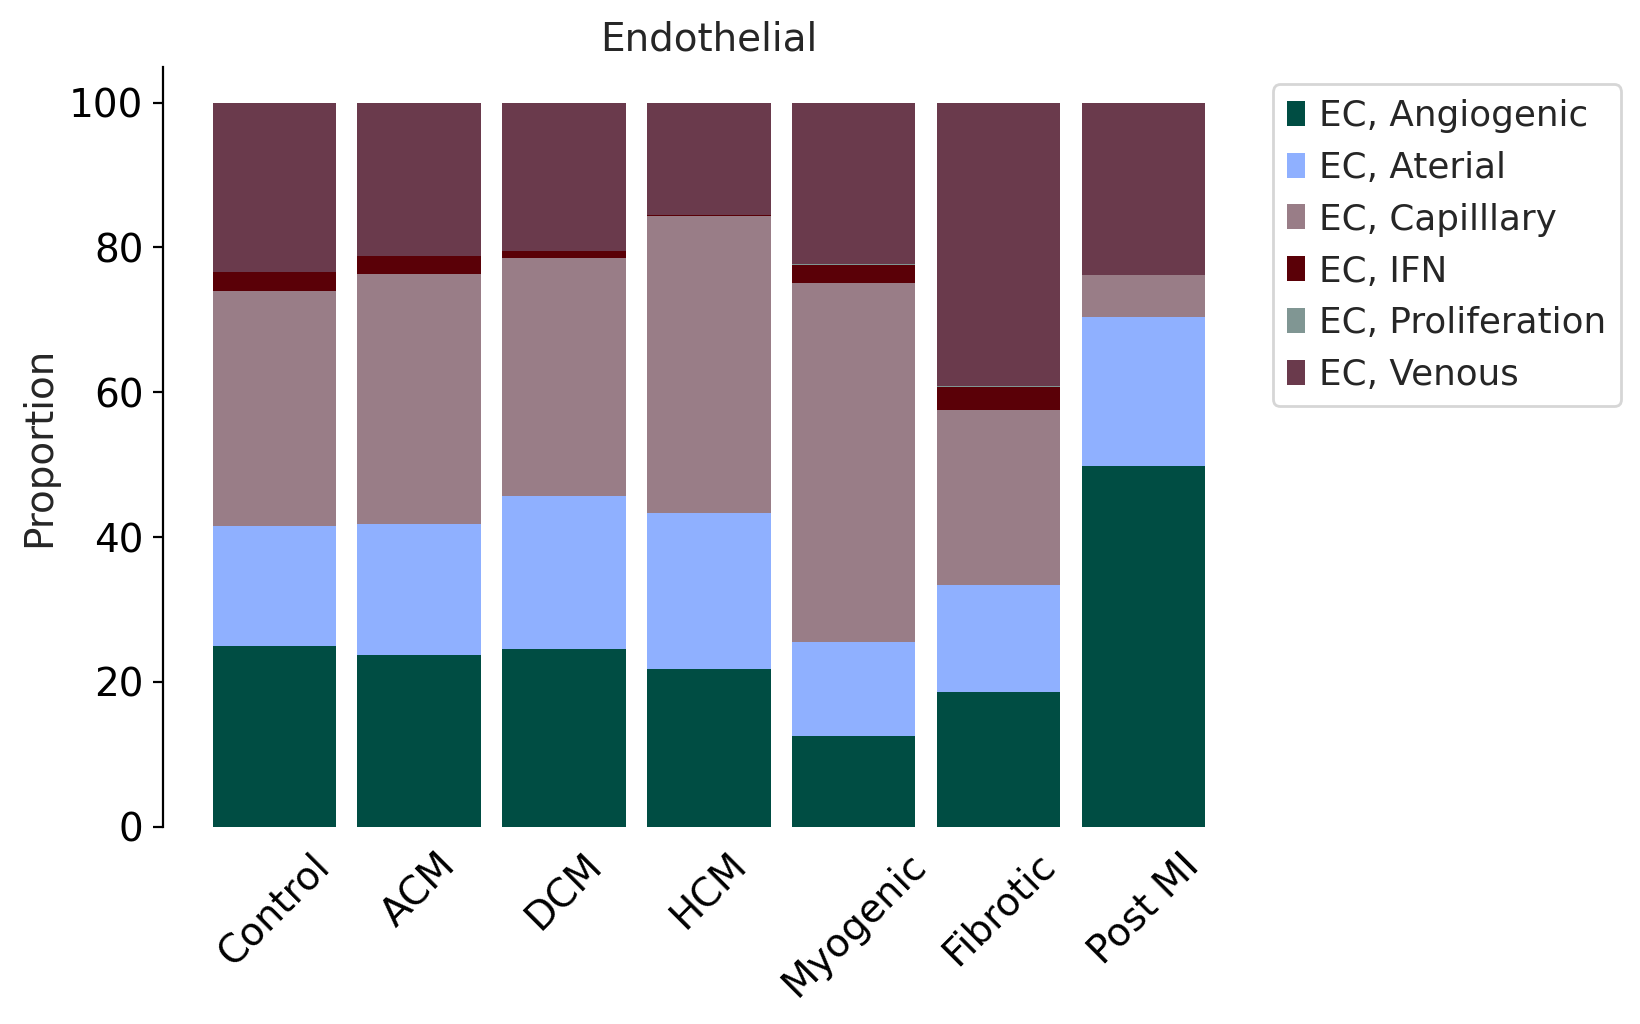

Mast cells


<Figure size 480x400 with 0 Axes>

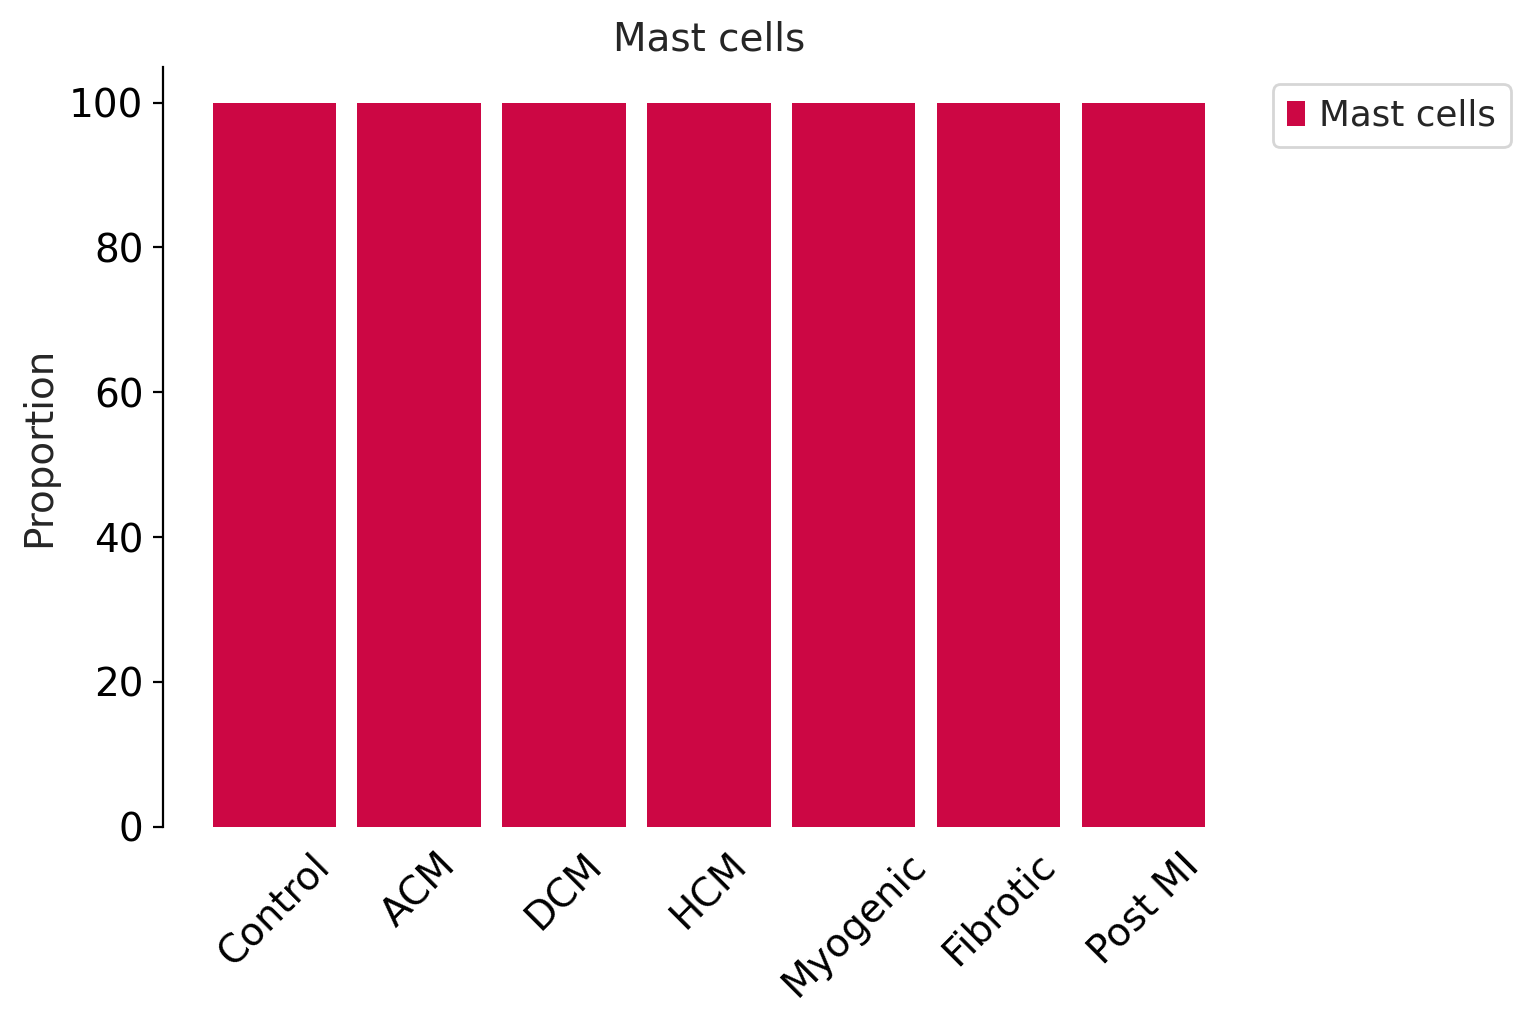

Neuronal


<Figure size 480x400 with 0 Axes>

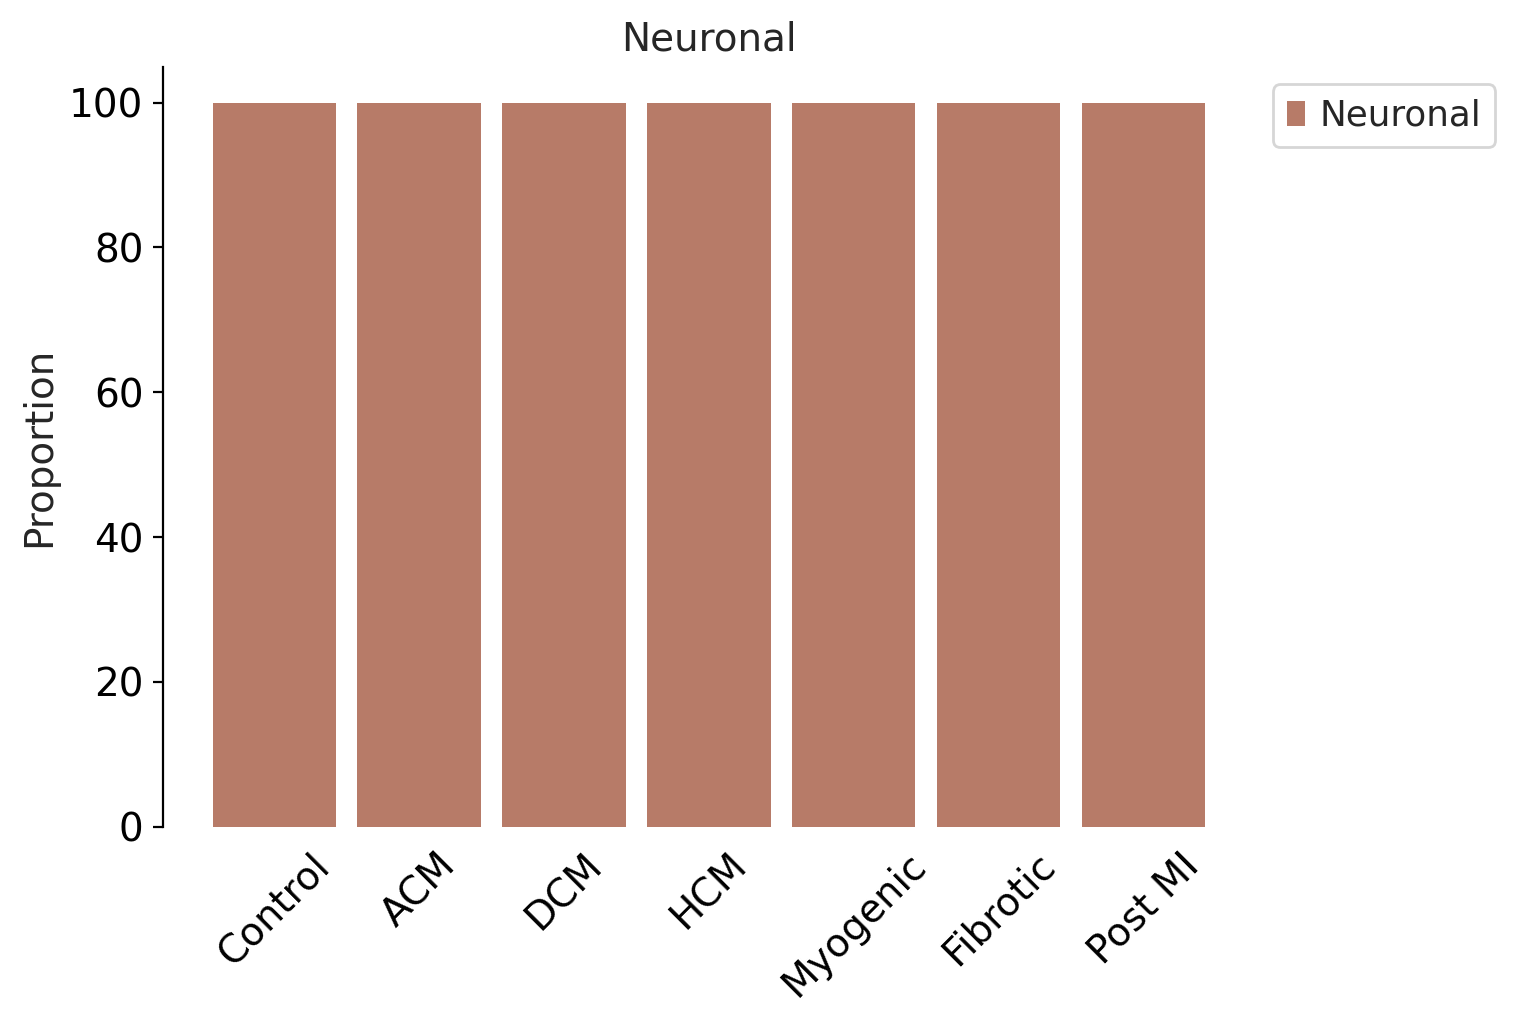

VSMC


<Figure size 480x400 with 0 Axes>

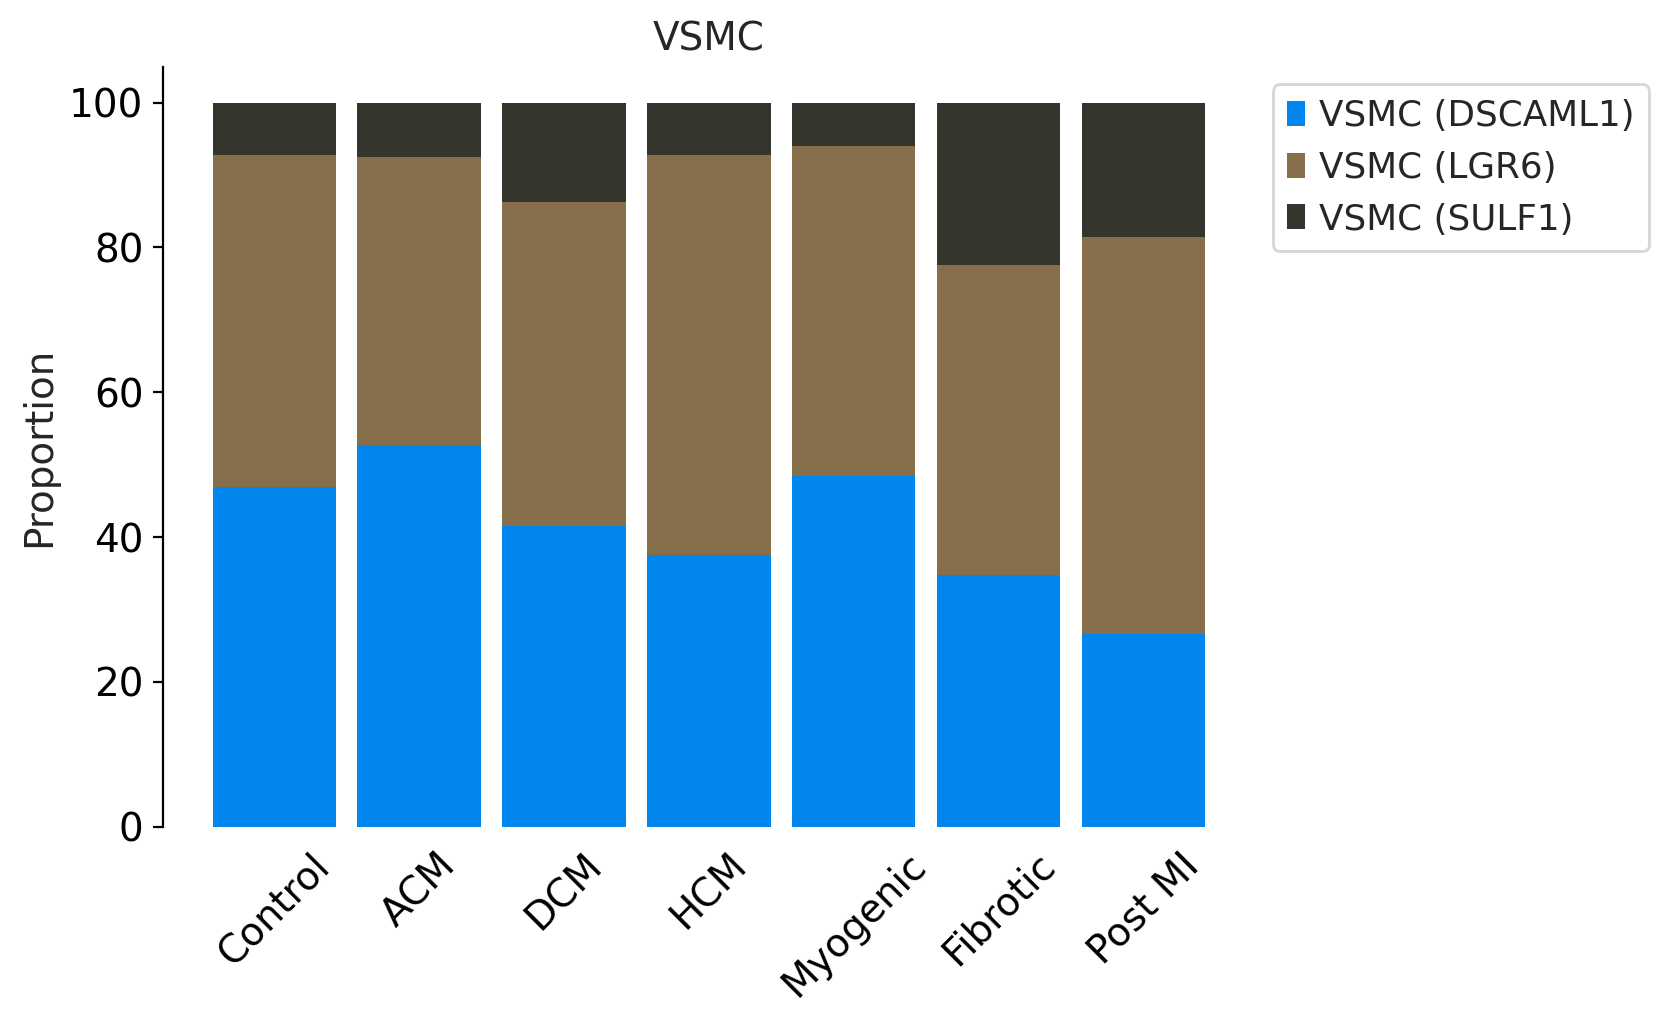

Myeloid


<Figure size 480x400 with 0 Axes>

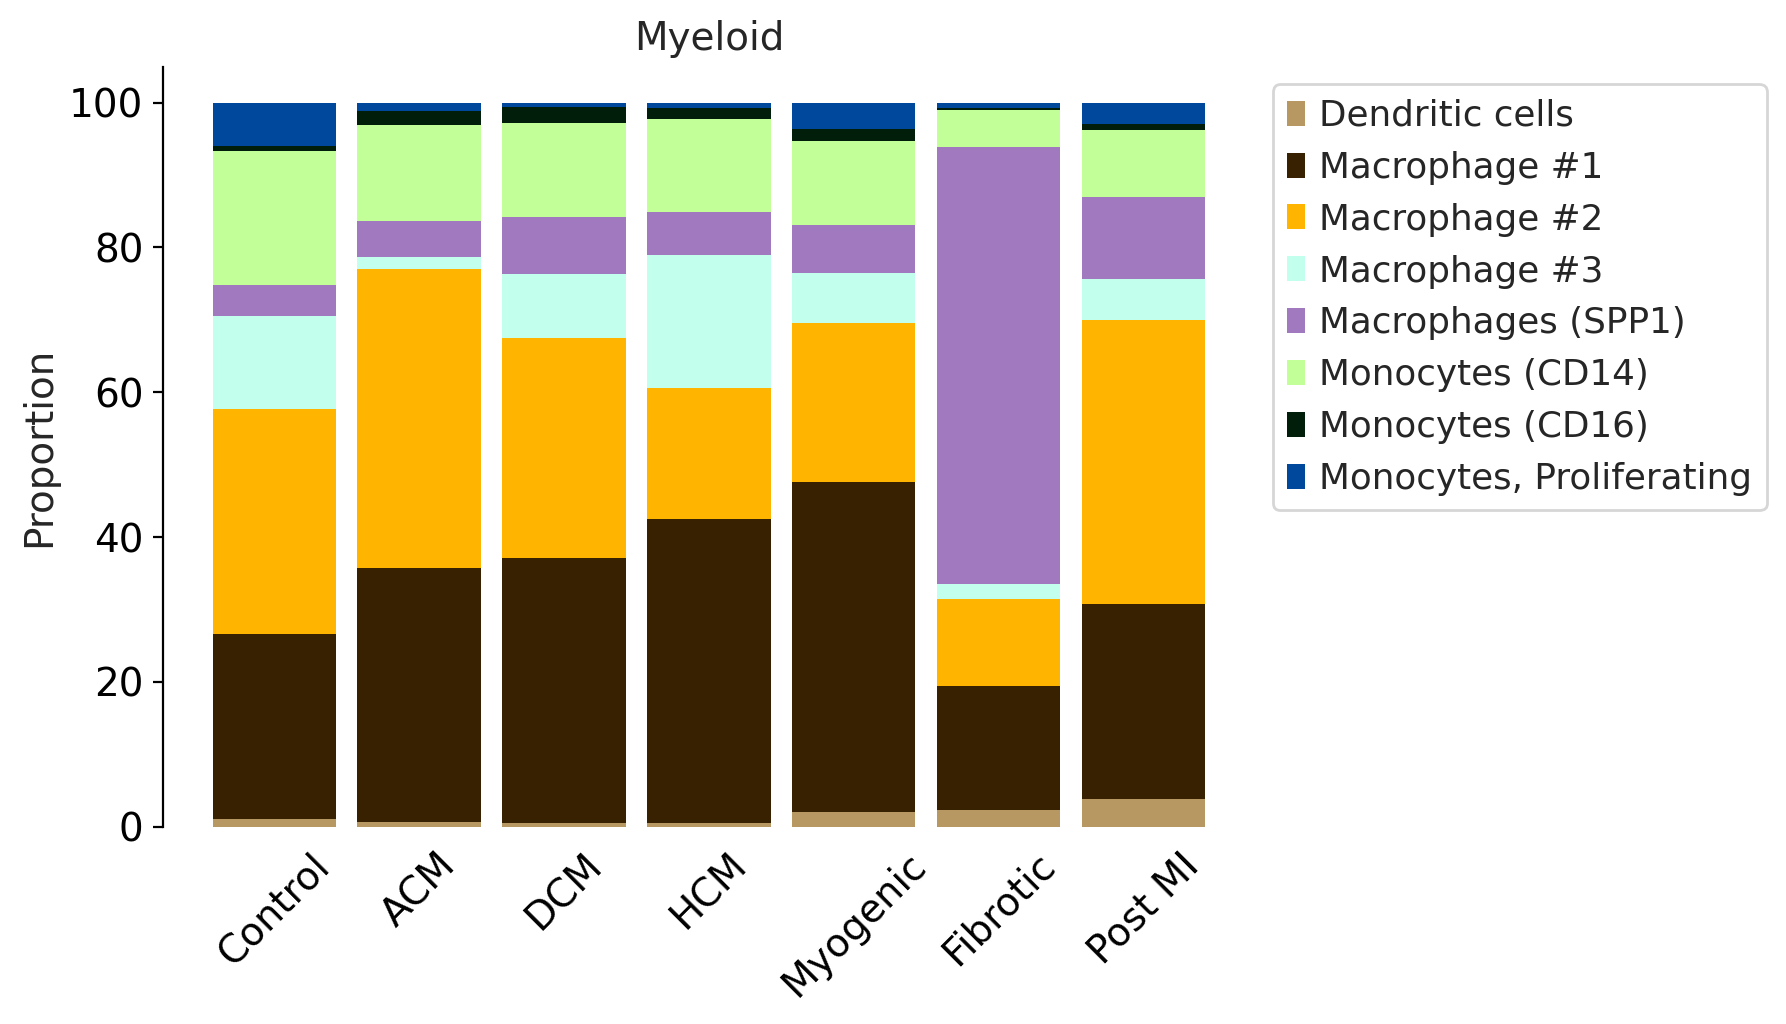

Adipocytes


<Figure size 480x400 with 0 Axes>

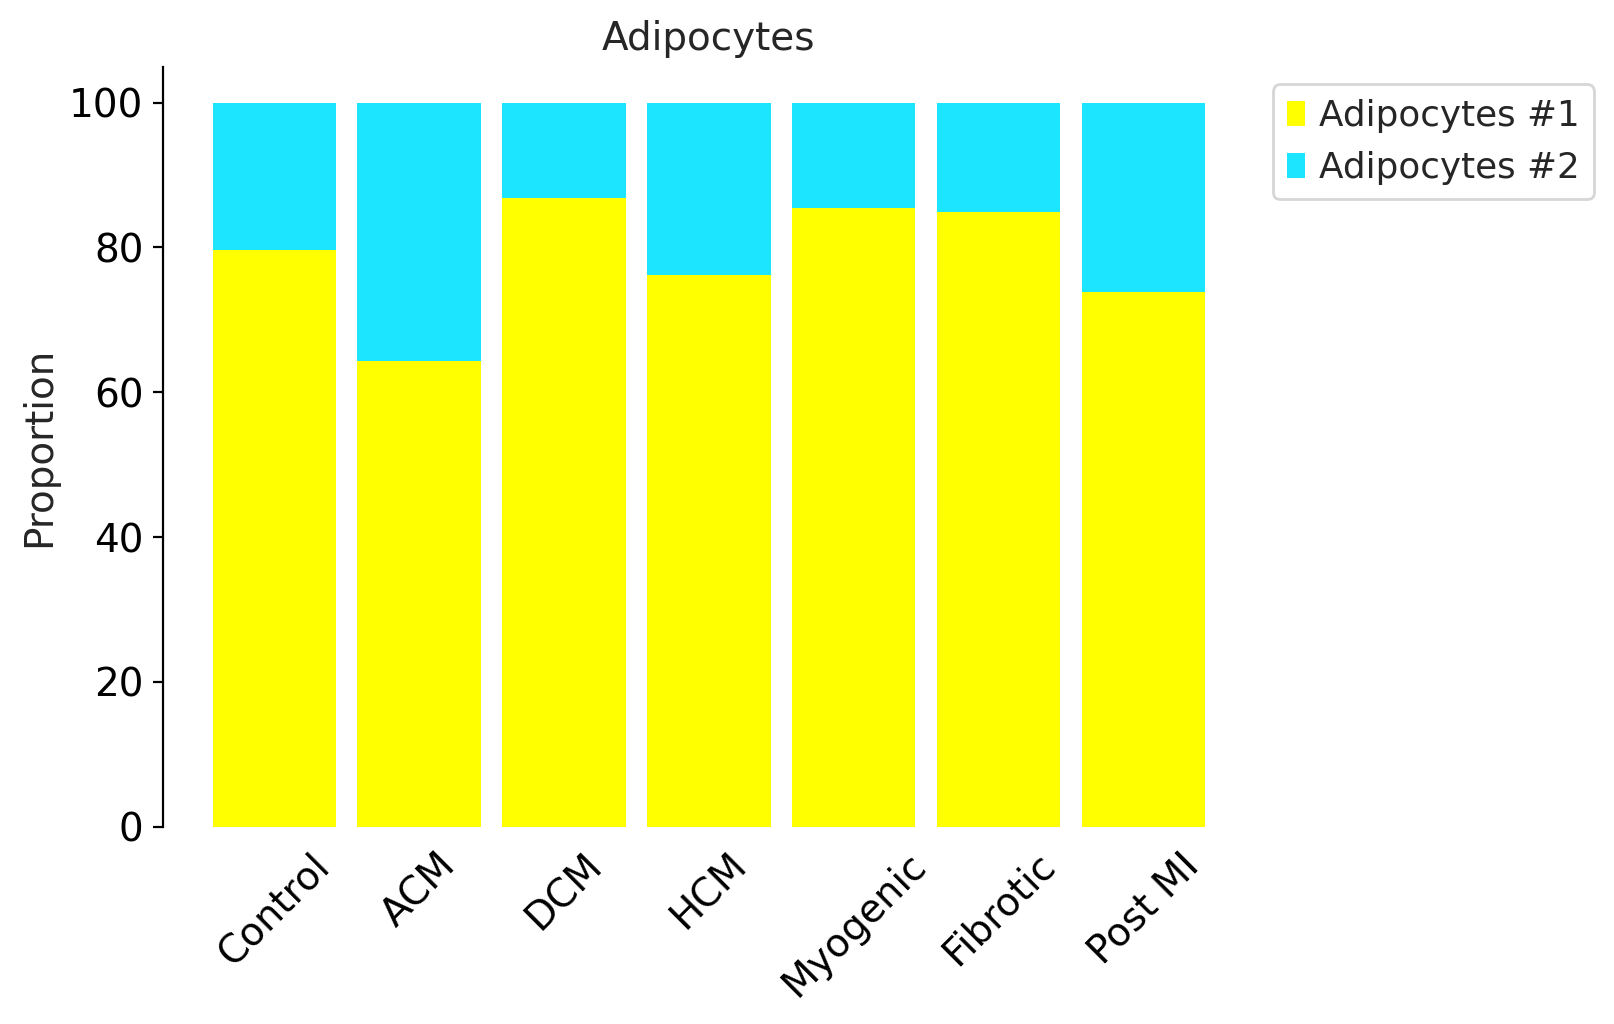

Endocardial


<Figure size 480x400 with 0 Axes>

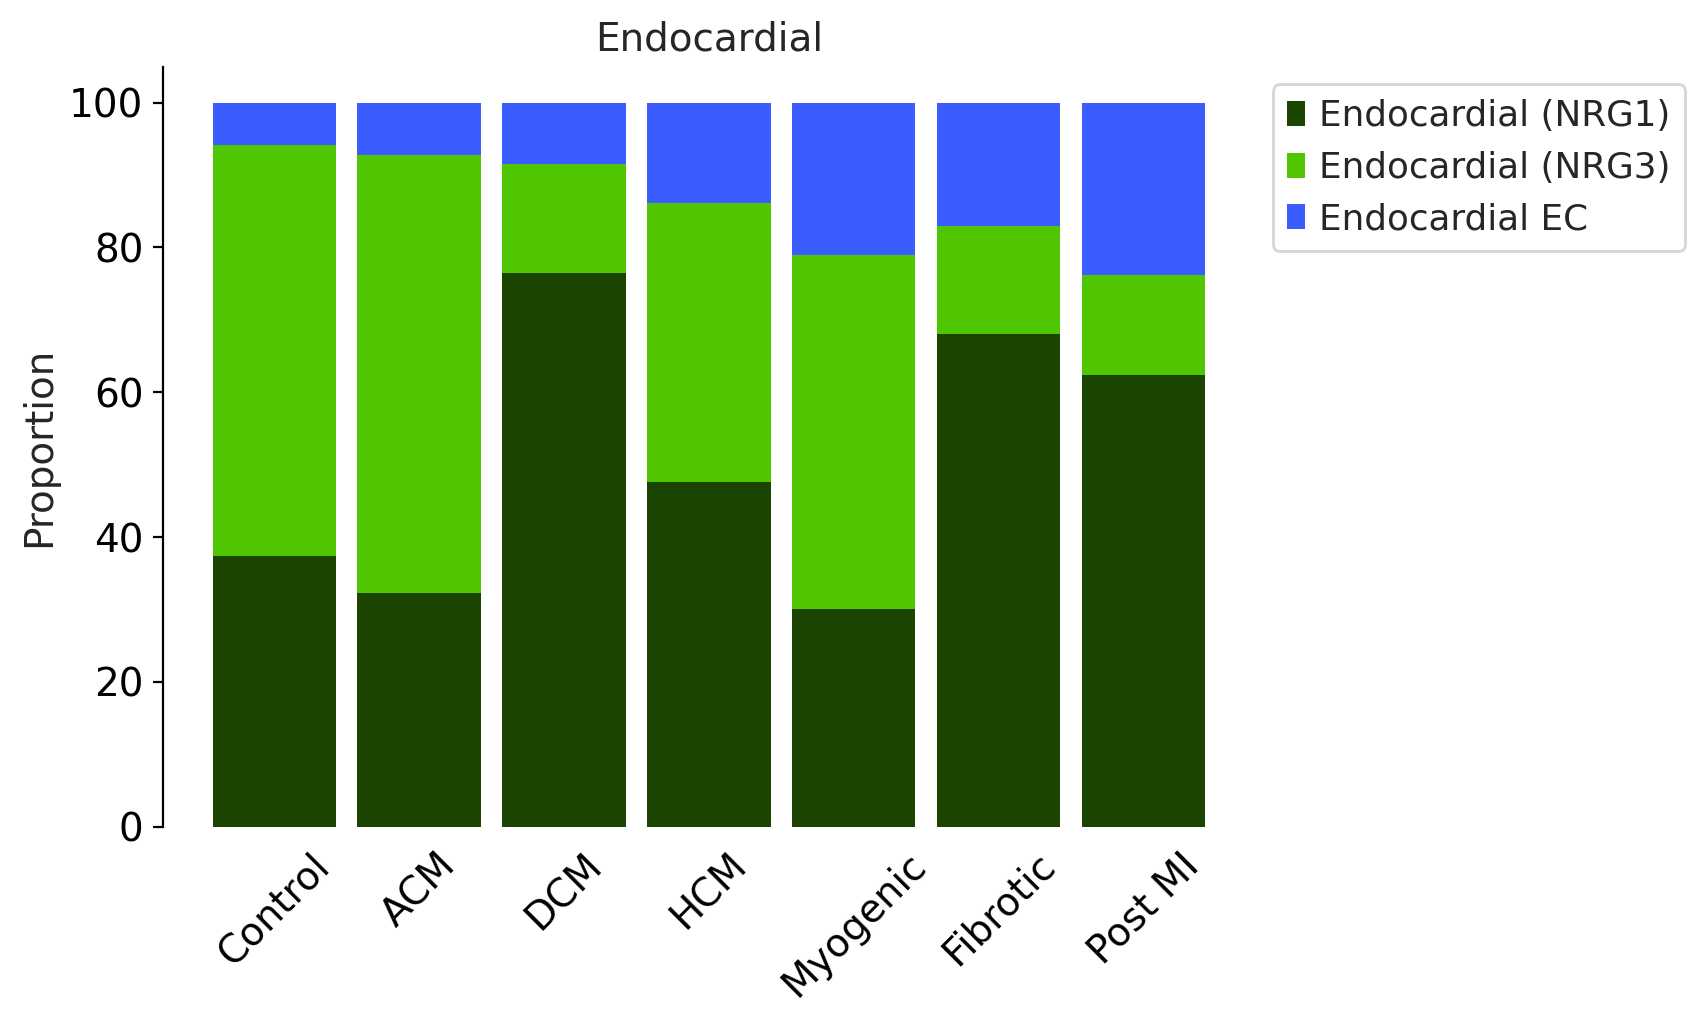

In [13]:
import matplotlib.colors as mcolors
gc.collect()
Heart = Heart[~Heart.obs["Condition"].isin(["Ischemic"]), :]
Heart = Heart[~Heart.obs["Annotation_1"].isin(["Ischemic cells (MI)"]), :]

#sc.set_figure_params(figsize=(9, 5))
sc.set_figure_params(figsize=(7, 5))
pdf_pages = PdfPages('Composition_Subclustering.pdf')

for cluster in Heart.obs["Annotation_2"].unique()[0:12]:
    print(cluster)
    plt.figure(figsize=(6, 5))
    subset = Heart[Heart.obs["Annotation_2"].isin([cluster])]
    subset = subset[~subset.obs["Subclustering"].isin(["Fibroblast (APOD/E)"]), :]
    subset = subset[~subset.obs["Subclustering"].isin(["Cardiomyocytes (LINGO1)"]), :]
    cross_table = pd.crosstab(index=[subset.obs["Donor"], subset.obs["Condition"]], columns=subset.obs["Subclustering_2"])
    cell_counts = cross_table.reset_index()
    compositions = dat.from_pandas(cell_counts, covariate_columns=["Donor", "Condition"])
    
    viz.stacked_barplot(compositions, feature_name="Condition", level_order=['Control', 'ACM', 'DCM', 'HCM', 'Myogenic', 'Fibrotic', 'Post MI'], cmap=mcolors.ListedColormap(subset.uns['Subclustering_2_colors']))
    plt.title(cluster)
    ax = plt.gca()
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(left=True, bottom=False)
    ax.grid(False)
    
    pdf_pages.savefig(plt.gcf(), bbox_inches='tight')
    plt.show()
pdf_pages.close()

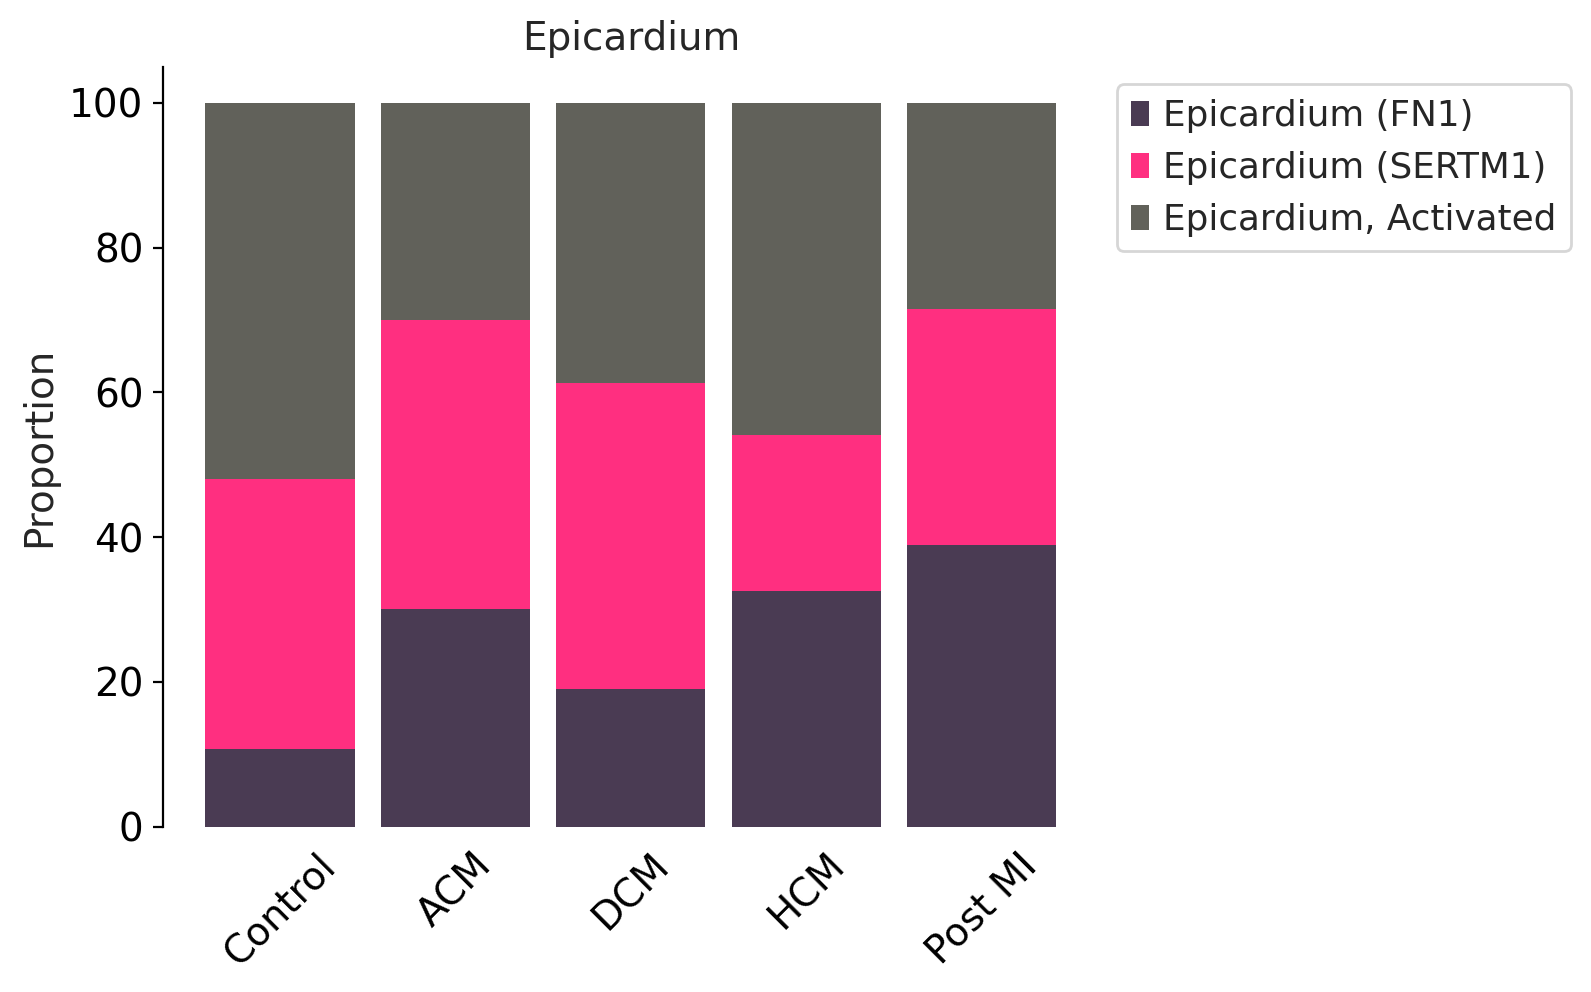

In [14]:
import matplotlib.colors as mcolors
subset = Heart[Heart.obs["Annotation_1"].isin(["Epicardium"]), :]
sc.set_figure_params(figsize=(6, 5))
cross_table = pd.crosstab(index=[subset.obs["Donor"], subset.obs["Condition"]], columns=subset.obs["Subclustering_2"])
cell_counts = cross_table.reset_index()
compositions = dat.from_pandas(cell_counts, covariate_columns=["Donor", "Condition"])
viz.stacked_barplot(compositions, feature_name="Condition", level_order=['Control', 'ACM', 'DCM', 'HCM', 'Post MI'], cmap=mcolors.ListedColormap(subset.uns['Subclustering_2_colors']))
plt.title("Epicardium")

ax = plt.gca()
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.tick_params(left=True, bottom=False)
ax.grid(False)
#pdf_pages.savefig(plt.gcf(), bbox_inches='tight')
plt.show()

Myeloid


<Figure size 480x400 with 0 Axes>

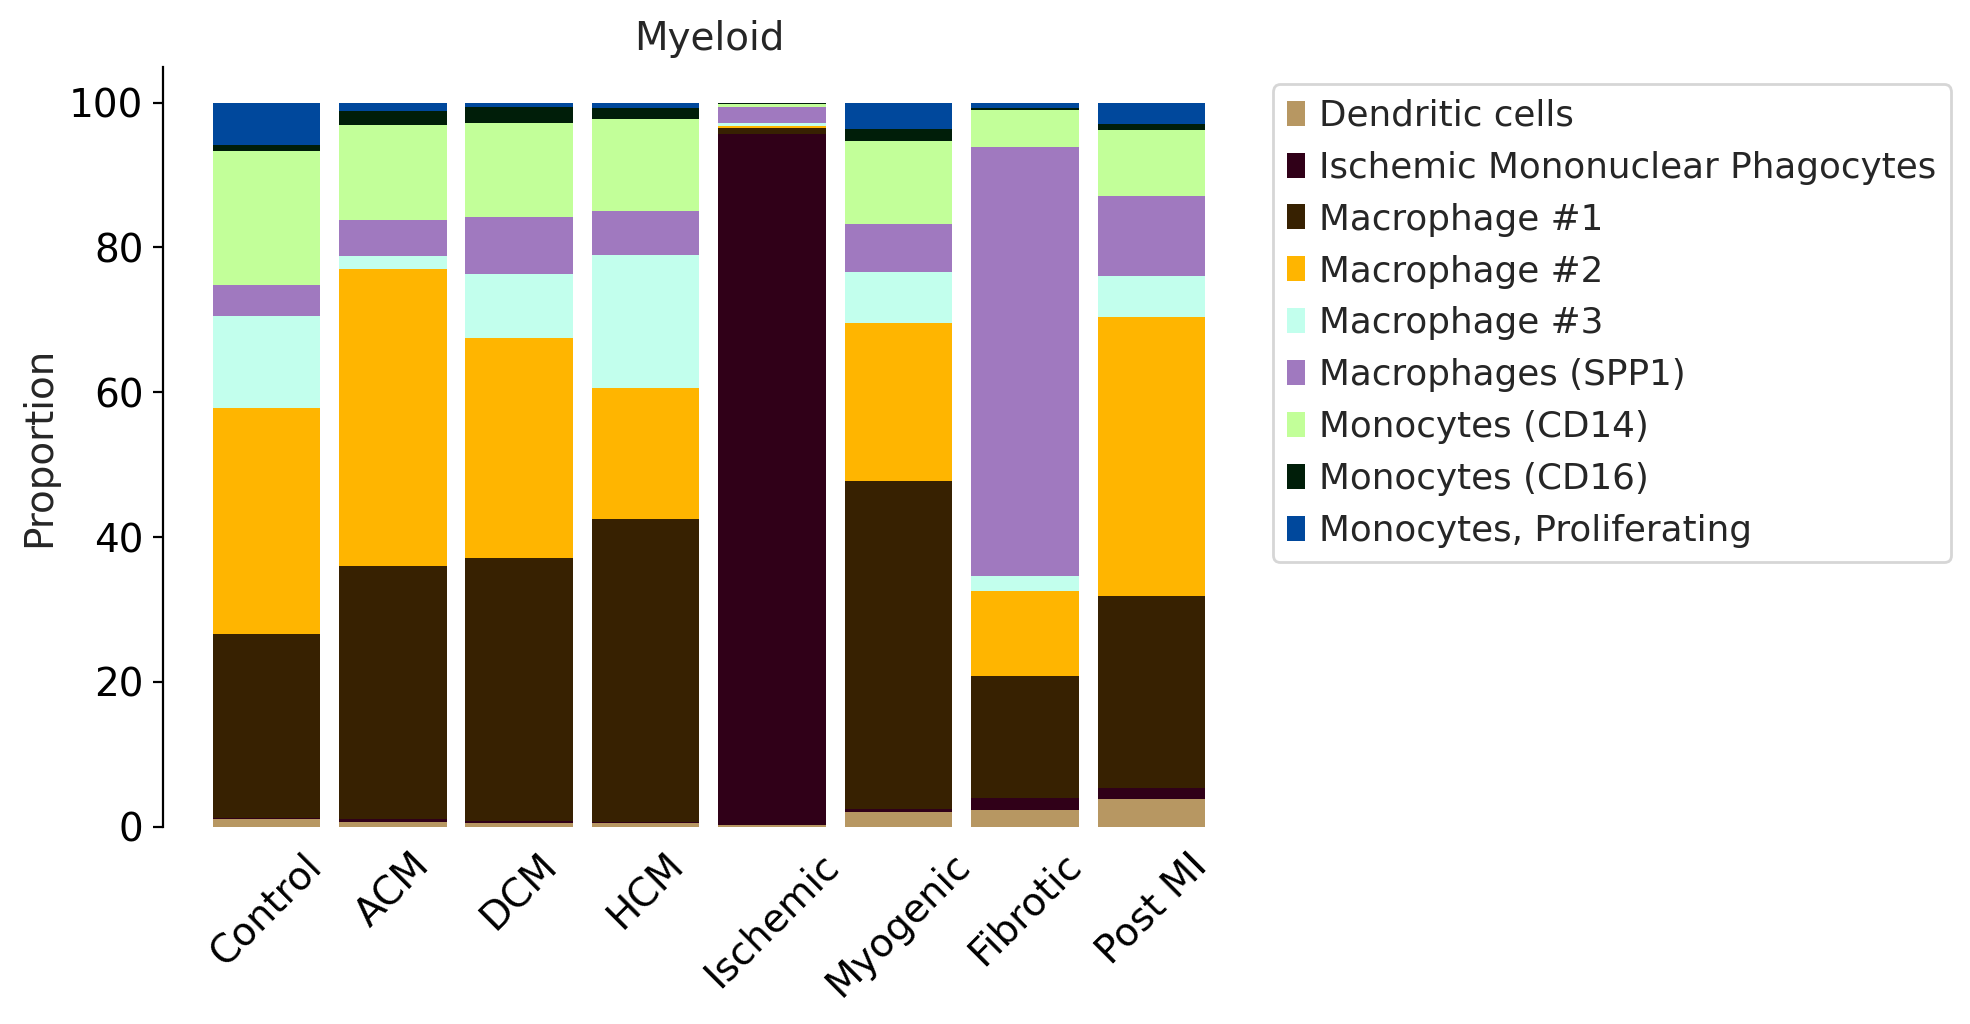

In [17]:
import matplotlib.colors as mcolors
gc.collect()
#Heart = Heart[~Heart.obs["Condition"].isin(["Ischemic"]), :]

#sc.set_figure_params(figsize=(9, 5))
sc.set_figure_params(figsize=(7, 5))
pdf_pages = PdfPages('Composition_Subclustering_Ischemic.pdf')

for cluster in Heart.obs["Annotation_2"].unique()[9:10]:
    print(cluster)
    plt.figure(figsize=(6, 5))
    subset = Heart[Heart.obs["Annotation_2"].isin([cluster])]
    cross_table = pd.crosstab(index=[subset.obs["Donor"], subset.obs["Condition"]], columns=subset.obs["Subclustering_2"])
    cell_counts = cross_table.reset_index()
    compositions = dat.from_pandas(cell_counts, covariate_columns=["Donor", "Condition"])
    
    viz.stacked_barplot(compositions, feature_name="Condition", level_order=['Control', 'ACM', 'DCM', 'HCM', 'Ischemic', 'Myogenic', 'Fibrotic', 'Post MI'], cmap=mcolors.ListedColormap(subset.uns['Subclustering_2_colors']))
    plt.title(cluster)
    ax = plt.gca()
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(left=True, bottom=False)
    ax.grid(False)
    
    pdf_pages.savefig(plt.gcf(), bbox_inches='tight')
    plt.show()
pdf_pages.close()

In [4]:
def make_unique_sheet_name(name, existing):
    # Replace forbidden characters and trim
    clean = re.sub(r'[\[\]\:\*\?\/\\]', '_', str(name))[:31] or "Sheet"
    base = clean
    i = 1
    while clean in existing:
        suffix = f"_{i}"
        clean = (base[:31 - len(suffix)] + suffix)
        i += 1
    existing.add(clean)
    return clean

clusters = Heart.obs["Annotation_2"].unique()

out_path = "Supplementary table 4 - Subtype compositions.xlsx"
existing_names = set()

with pd.ExcelWriter(out_path, engine="xlsxwriter") as writer:
    for cluster in clusters:
        print(f"Processing: {cluster}")

        # Subset data
        subset = Heart[Heart.obs["Annotation_2"].isin([cluster])]

        # Build composition table: counts of Subclustering_2 per Donor/Condition
        cross_table = pd.crosstab(
            index=[subset.obs["Donor"], subset.obs["Condition"]],
            columns=subset.obs["Subclustering_2"]
        )
        compositions_df = cross_table.reset_index()

        # Write to excel sheet
        sheet = make_unique_sheet_name(cluster, existing_names)
        compositions_df.to_excel(writer, sheet_name=sheet, index=False)

        worksheet = writer.sheets[sheet]
        for col_idx, col in enumerate(compositions_df.columns, start=0):
            # Width based on header and sample data
            max_len = max(
                [len(str(col))] + [len(str(x)) for x in compositions_df[col].astype(str).values[:200]]
            )
            worksheet.set_column(col_idx, col_idx, min(40, max(10, max_len + 2)))

print(f"Wrote: {out_path}")

Processing: Pericytes
Processing: Cardiomyocytes
Processing: Lymphatic EC
Processing: Fibroblast
Processing: Lymphocytes
Processing: Endothelial
Processing: Mast cells
Processing: Neuronal
Processing: VSMC
Processing: Myeloid
Processing: Adipocytes
Processing: Endocardial
Processing: Epicardium
Wrote: Supplementary table 3 - Subtype compositions.xlsx


In [34]:
def sankey_from_obs(
    adata,
    source_col: str,
    target_col: str,
    *,
    normalize: str | None = None,   # None | 'source' | 'total'
    min_count: int = 1,
    source_order: list[str] | None = None,
    target_order: list[str] | None = None,
    title: str | None = None,
    width: int = 1100,
    height: int = 600
):
    """
    Build a Sankey plot showing flow counts from adata.obs[source_col] to adata.obs[target_col].
    Link and right-node colors are taken from adata.uns['Subclustering_2_colors'] via ListedColormap
    (and aligned to target_col categories/order).
    """
    obs = adata.obs[[source_col, target_col]].copy().dropna(subset=[source_col, target_col])

    def ordered_levels(series, explicit):
        if explicit is not None:
            return list(explicit)
        if pd.api.types.is_categorical_dtype(series):
            return list(series.cat.categories)
        return pd.Index(series.astype(str)).drop_duplicates().tolist()

    src_levels = ordered_levels(obs[source_col], source_order)
    tgt_levels = ordered_levels(obs[target_col], target_order)

    # ensure string labels for counting
    obs[source_col] = obs[source_col].astype(str)
    obs[target_col] = obs[target_col].astype(str)

    # counts in chosen order
    ct = pd.crosstab(obs[source_col], obs[target_col]).reindex(index=src_levels, columns=tgt_levels, fill_value=0)

    # edges
    edges = (
        ct.stack()
          .reset_index(name="value")
          .query("value >= @min_count")
          .copy()
    )

    # normalization
    if normalize == "source":
        edges["value"] = edges["value"] / edges.groupby(source_col)["value"].transform("sum") * 100.0
    elif normalize == "total":
        total = edges["value"].sum()
        if total > 0:
            edges["value"] = edges["value"] / total * 100.0

    # nodes
    node_labels_left  = src_levels
    node_labels_right = tgt_levels
    node_labels = node_labels_left + node_labels_right

    idx_left  = {lab: i for i, lab in enumerate(node_labels_left)}
    idx_right = {lab: i + len(node_labels_left) for i, lab in enumerate(node_labels_right)}

    sources = edges[source_col].map(idx_left).to_numpy()
    targets = edges[target_col].map(idx_right).to_numpy()
    values  = edges["value"].to_numpy()

    target_colors_list = list(mcolors.ListedColormap(adata.uns['Subclustering_2_colors']).colors)

    # Map colors to target categories in their categorical order (if any), else in tgt_levels order
    if pd.api.types.is_categorical_dtype(adata.obs[target_col]):
        target_cats = list(adata.obs[target_col].cat.categories)
    else:
        target_cats = tgt_levels

    color_map_right = {cat: target_colors_list[i % len(target_colors_list)]
                       for i, cat in enumerate(target_cats)}

    # node colors
    node_colors_left  = ["#cccccc"] * len(node_labels_left)
    node_colors_right = [color_map_right.get(lab, "#999999") for lab in node_labels_right]

    # link colors
    link_colors = [color_map_right.get(t, "#999999") for t in edges[target_col]]

    fig = go.Figure(data=[
        go.Sankey(
            arrangement="snap",
            valueformat=".2f" if normalize else "d",
            node=dict(
                pad=15, thickness=18,
                label=node_labels,
                color=node_colors_left + node_colors_right
            ),
            link=dict(
                source=sources,
                target=targets,
                value=values,
                color=link_colors
            )
        )
    ])

    fig.update_layout(
        title=dict(text=title or f"{source_col} → {target_col}", x=0.5),
        font_size=12,
        width=width, height=height
    )
    return fig


In [44]:
FIB.obs["Study_Subcluster"] = FIB.obs["Study"].astype(str) + "_" + FIB.obs["Subcluster"].astype(str)
fig = sankey_from_obs(FIB, "Study_Subcluster", "Subclustering_2", normalize="total", min_count=30,
                     width=650,
    height=600)

fig.show()
fig.write_html("sankey_condition_to_celltype.html")

/w0/tmp/slurm_uv525372.60623801/ipykernel_3969732/2351185696.py:30: DeprecationWarning:

is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead

/w0/tmp/slurm_uv525372.60623801/ipykernel_3969732/2351185696.py:30: DeprecationWarning:

is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead

/w0/tmp/slurm_uv525372.60623801/ipykernel_3969732/2351185696.py:78: DeprecationWarning:

is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead



Pericytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

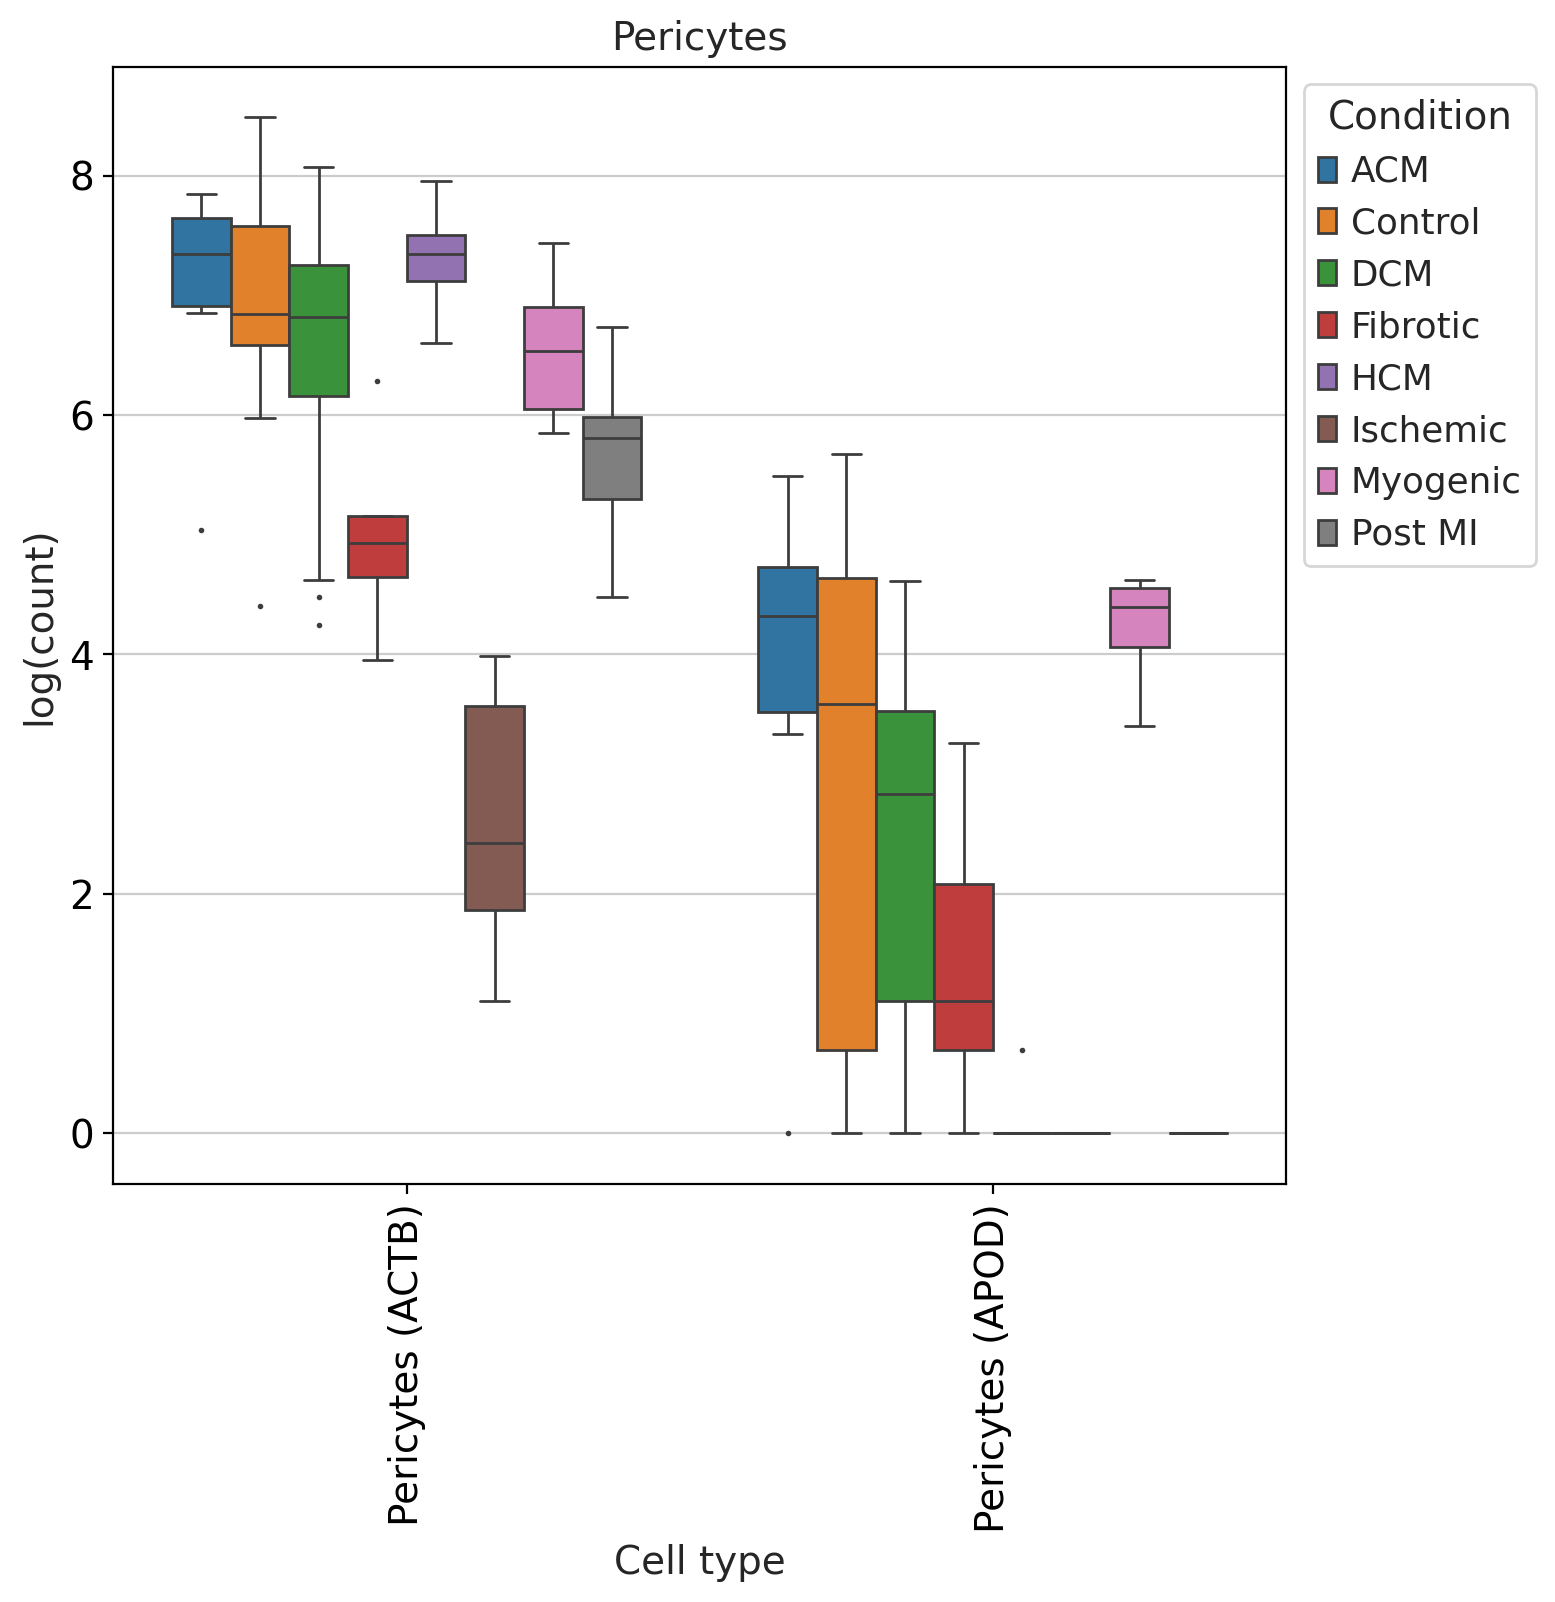

Cardiomyocytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

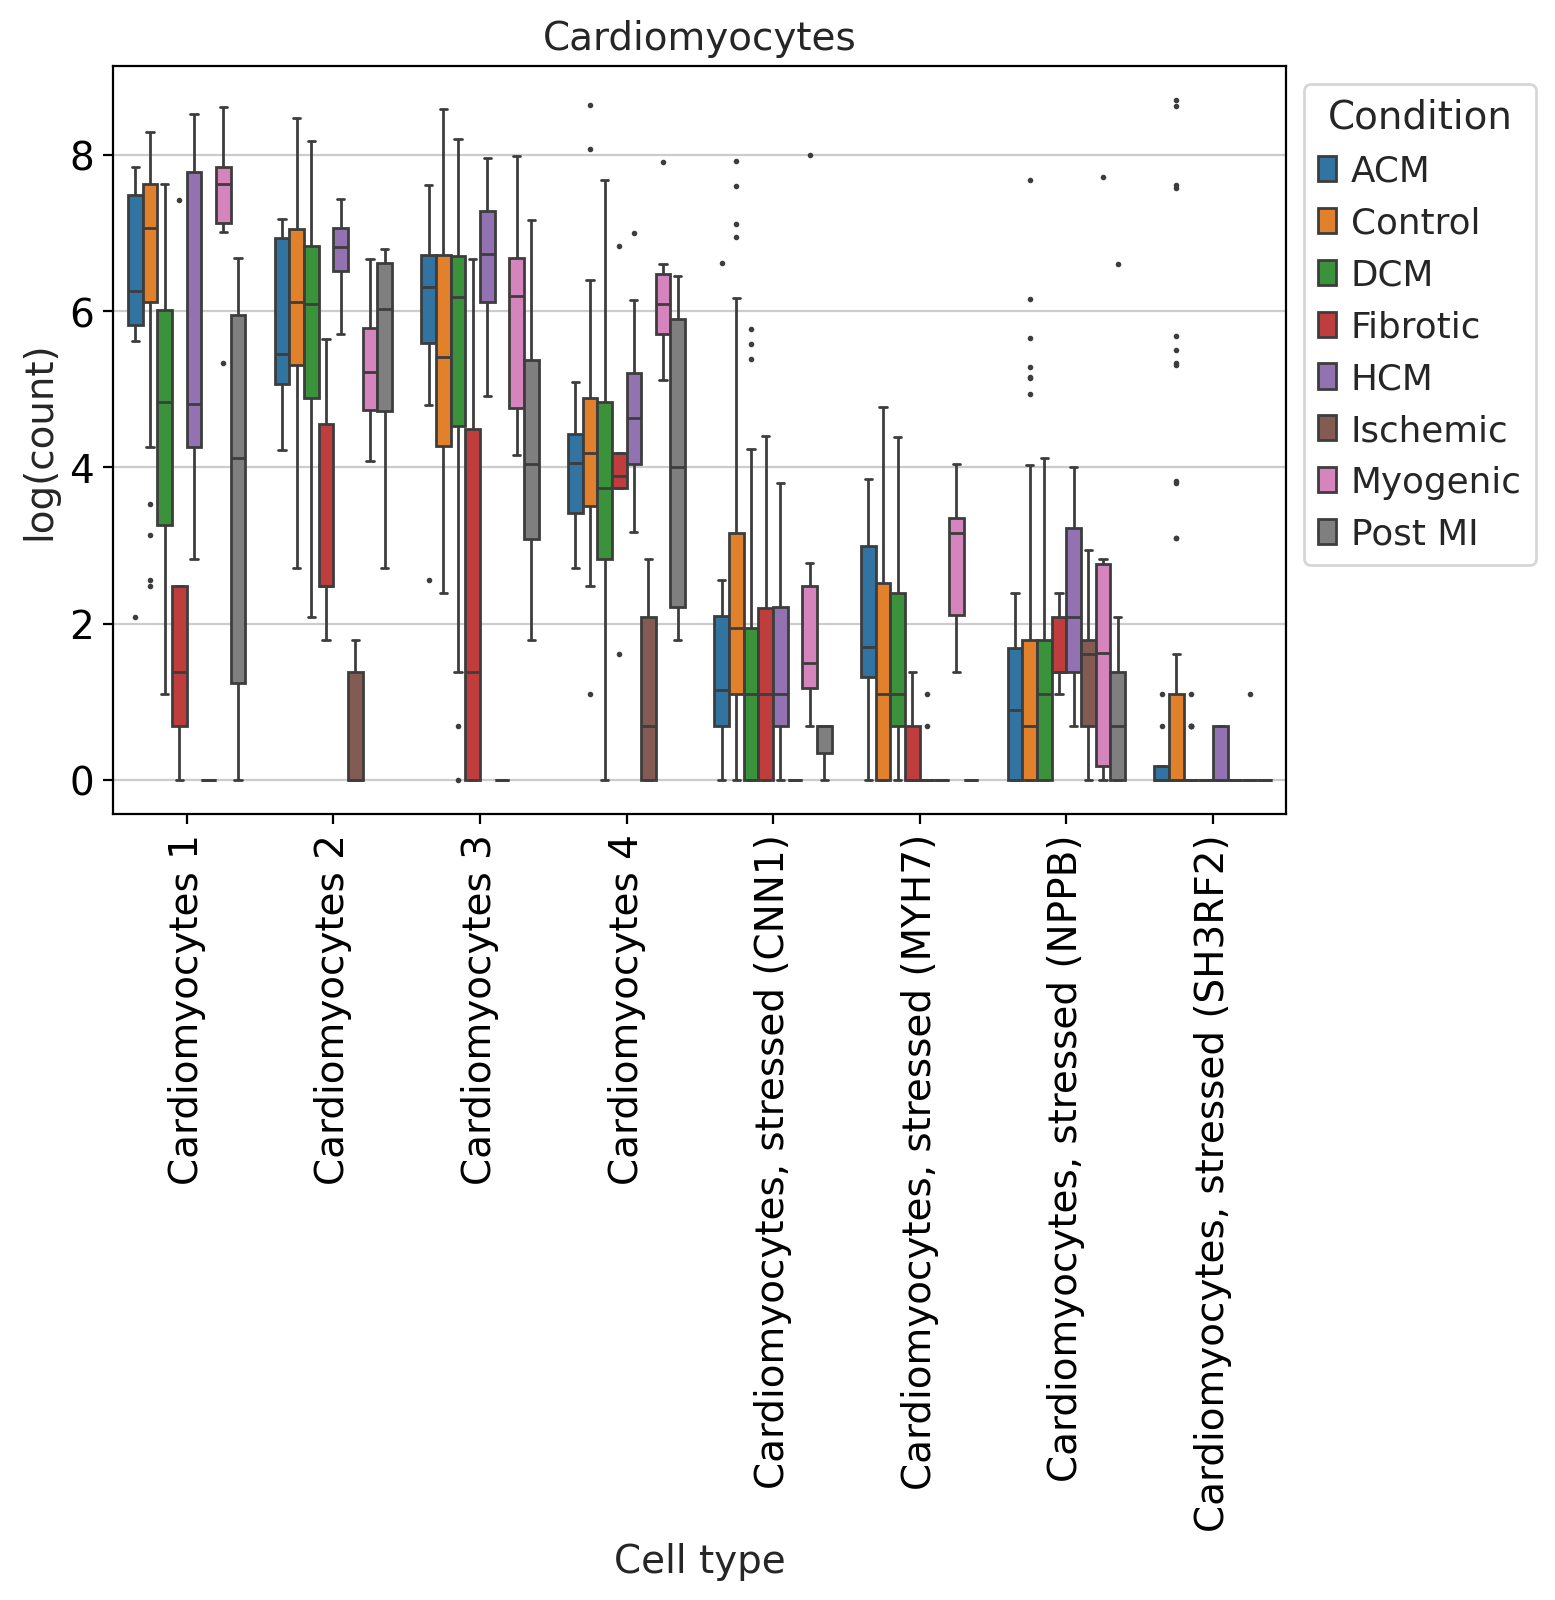

Lymphatic EC


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

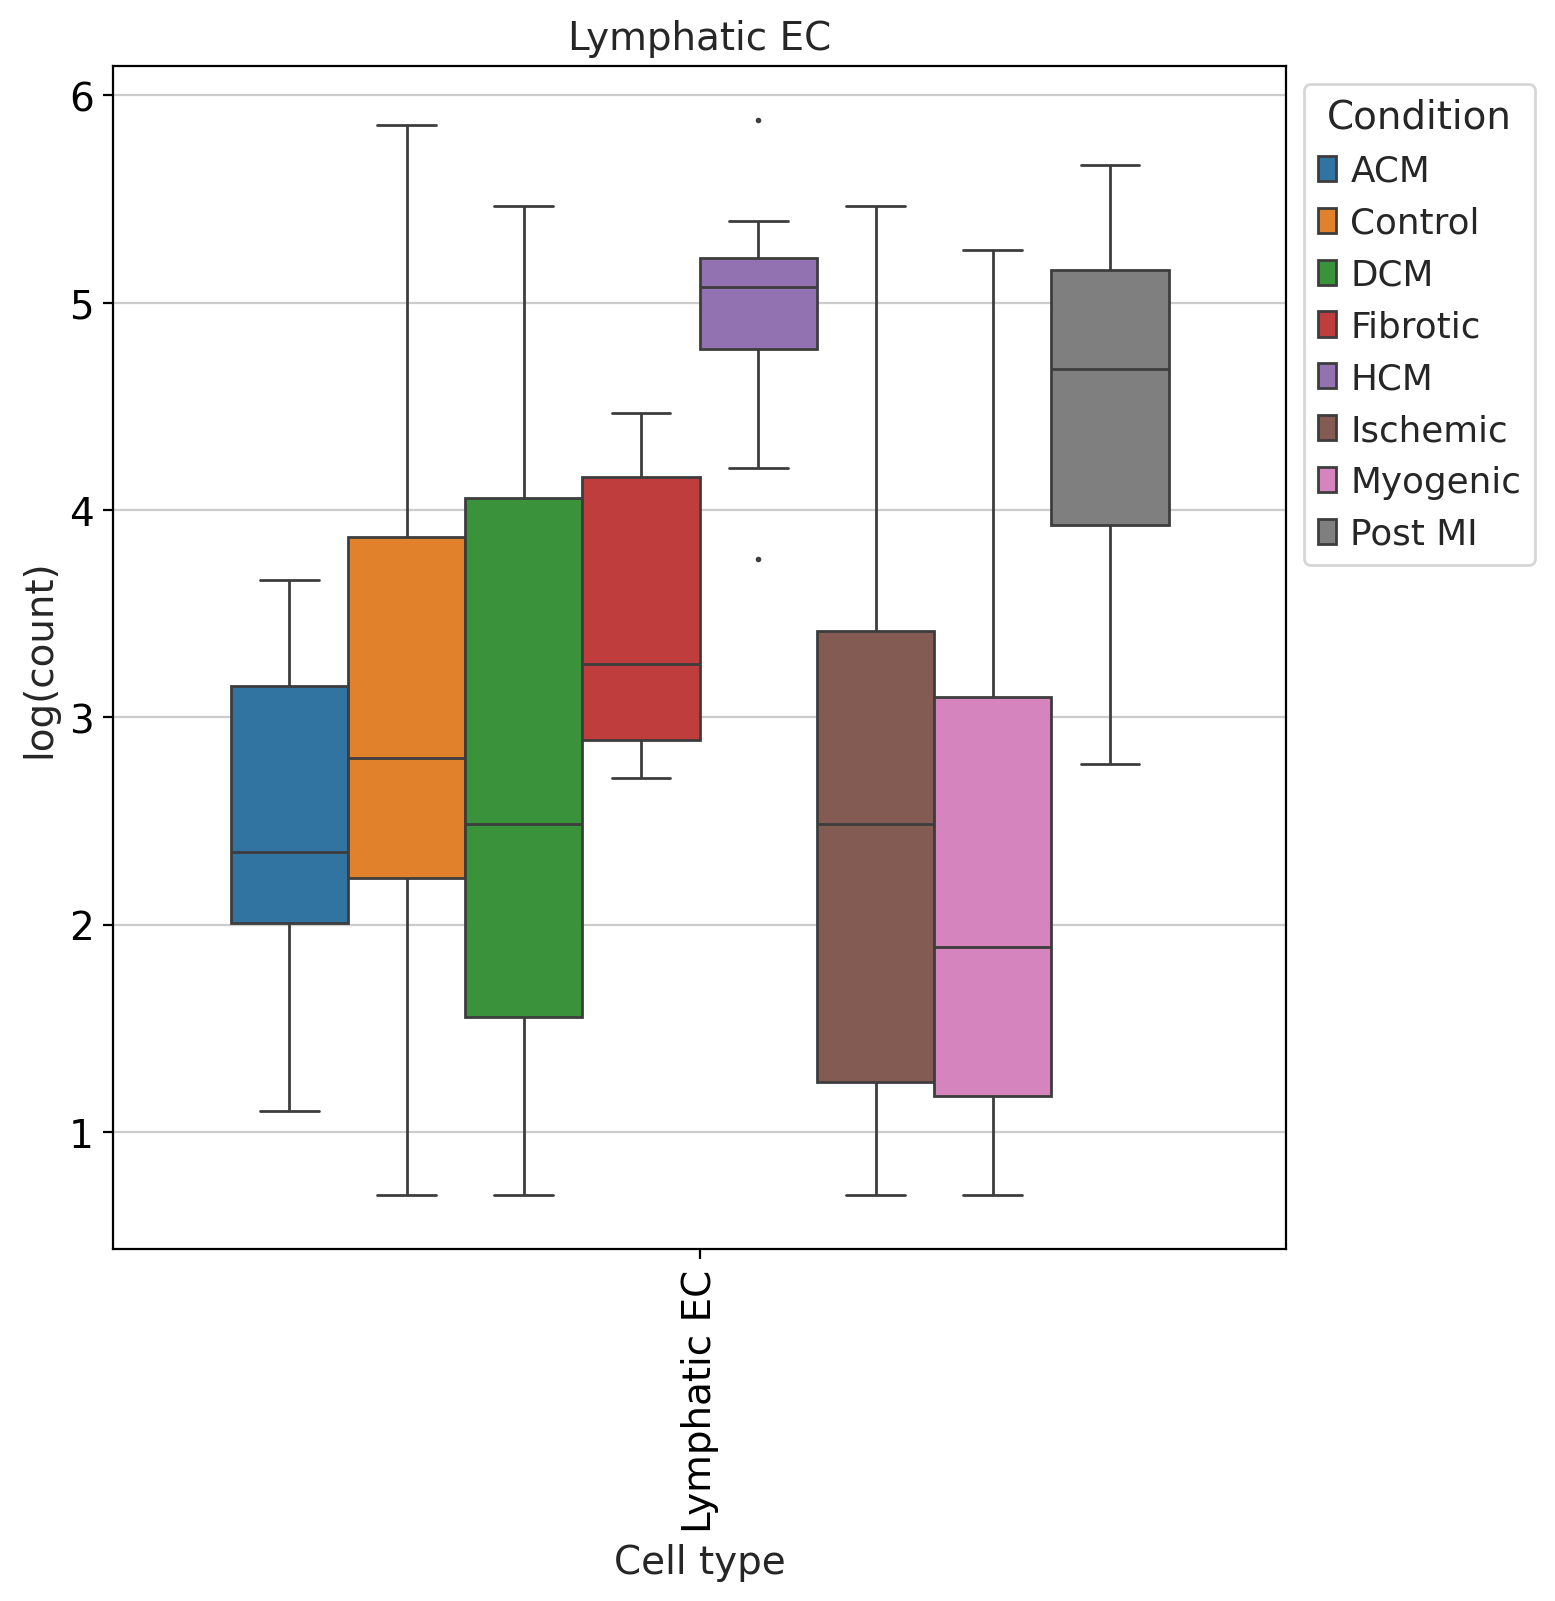

Fibroblast


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

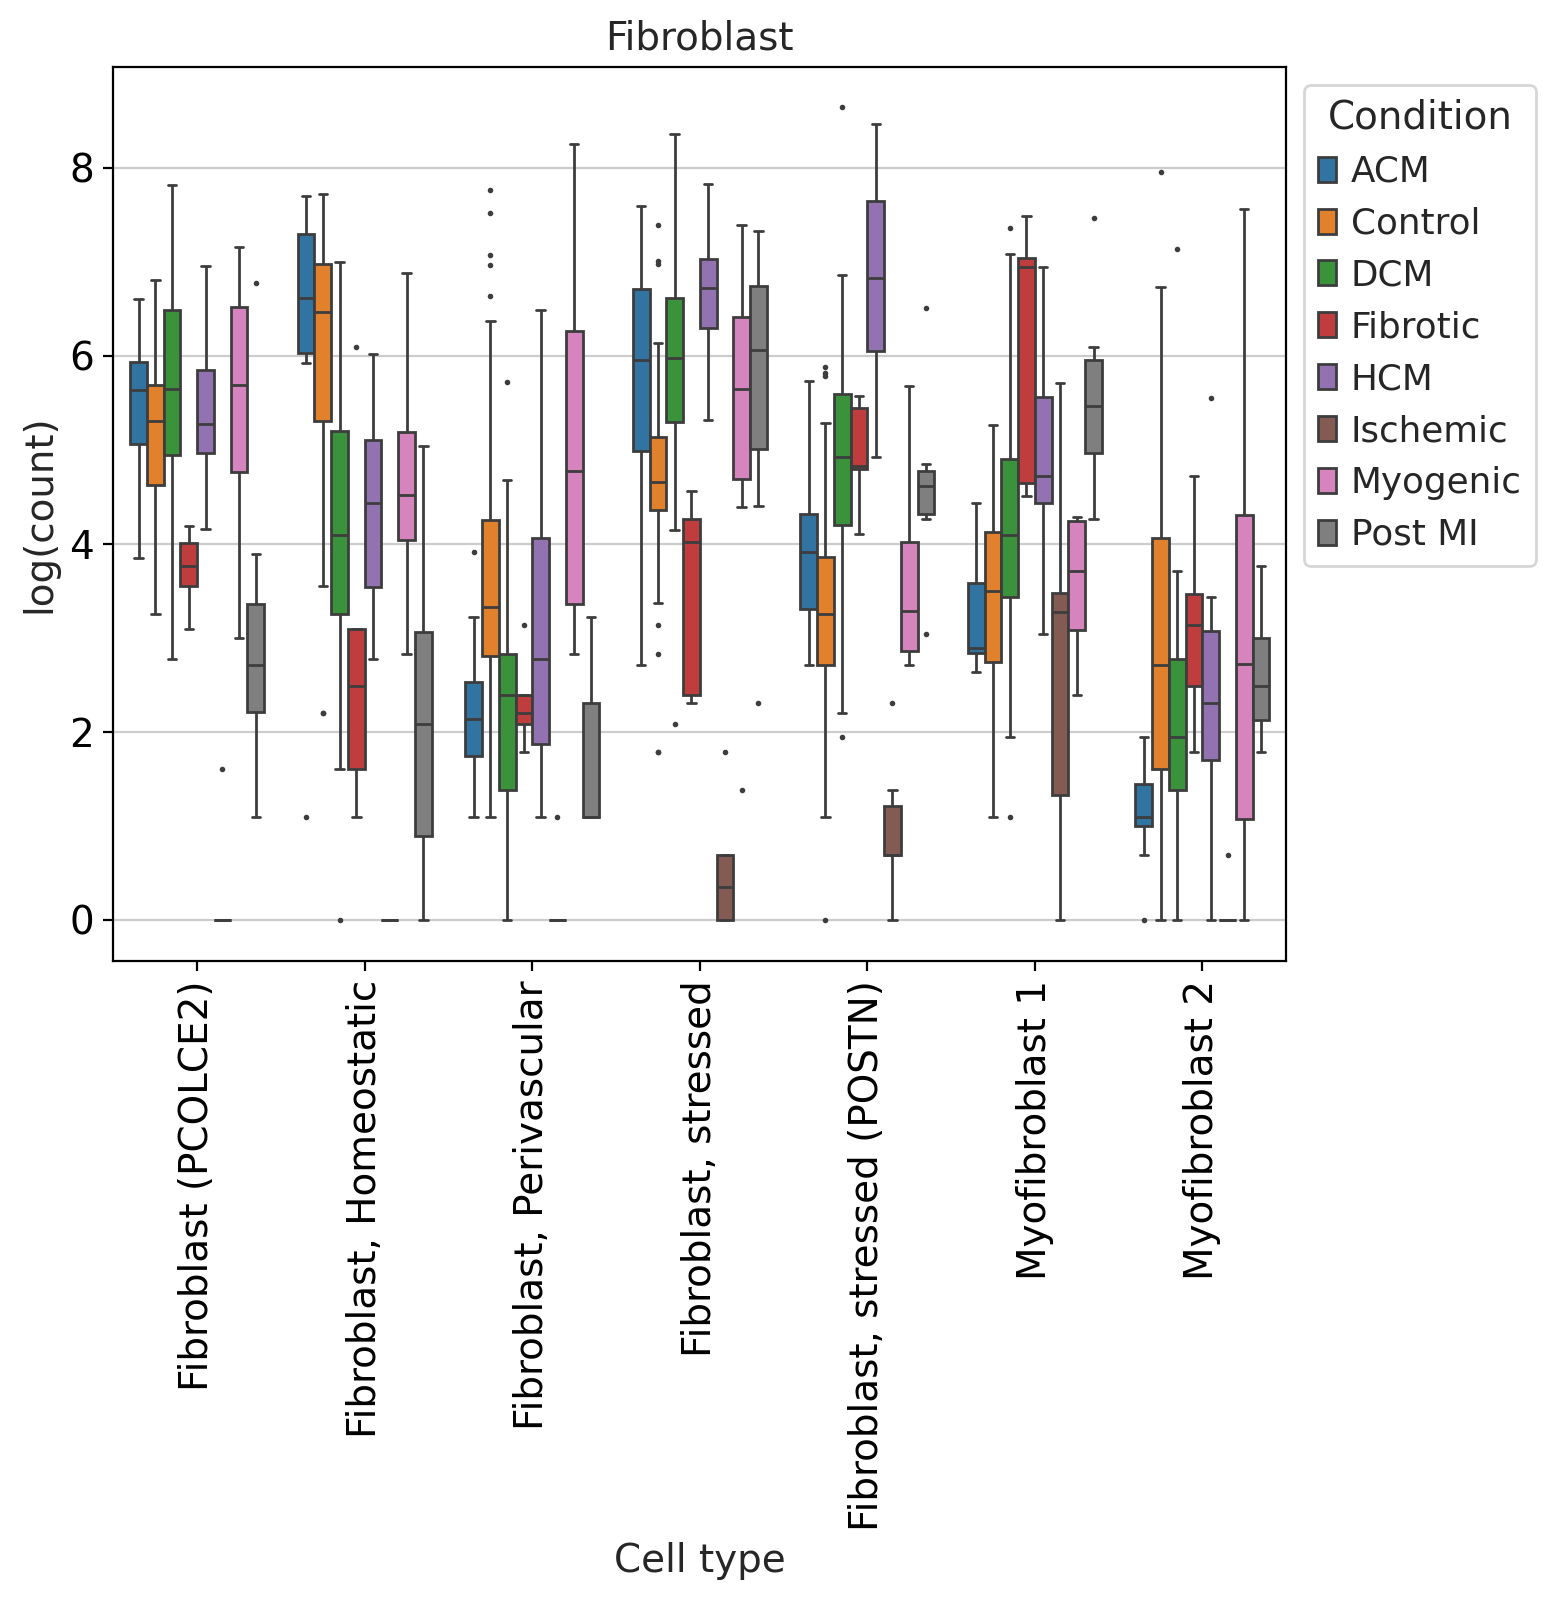

Lymphocytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

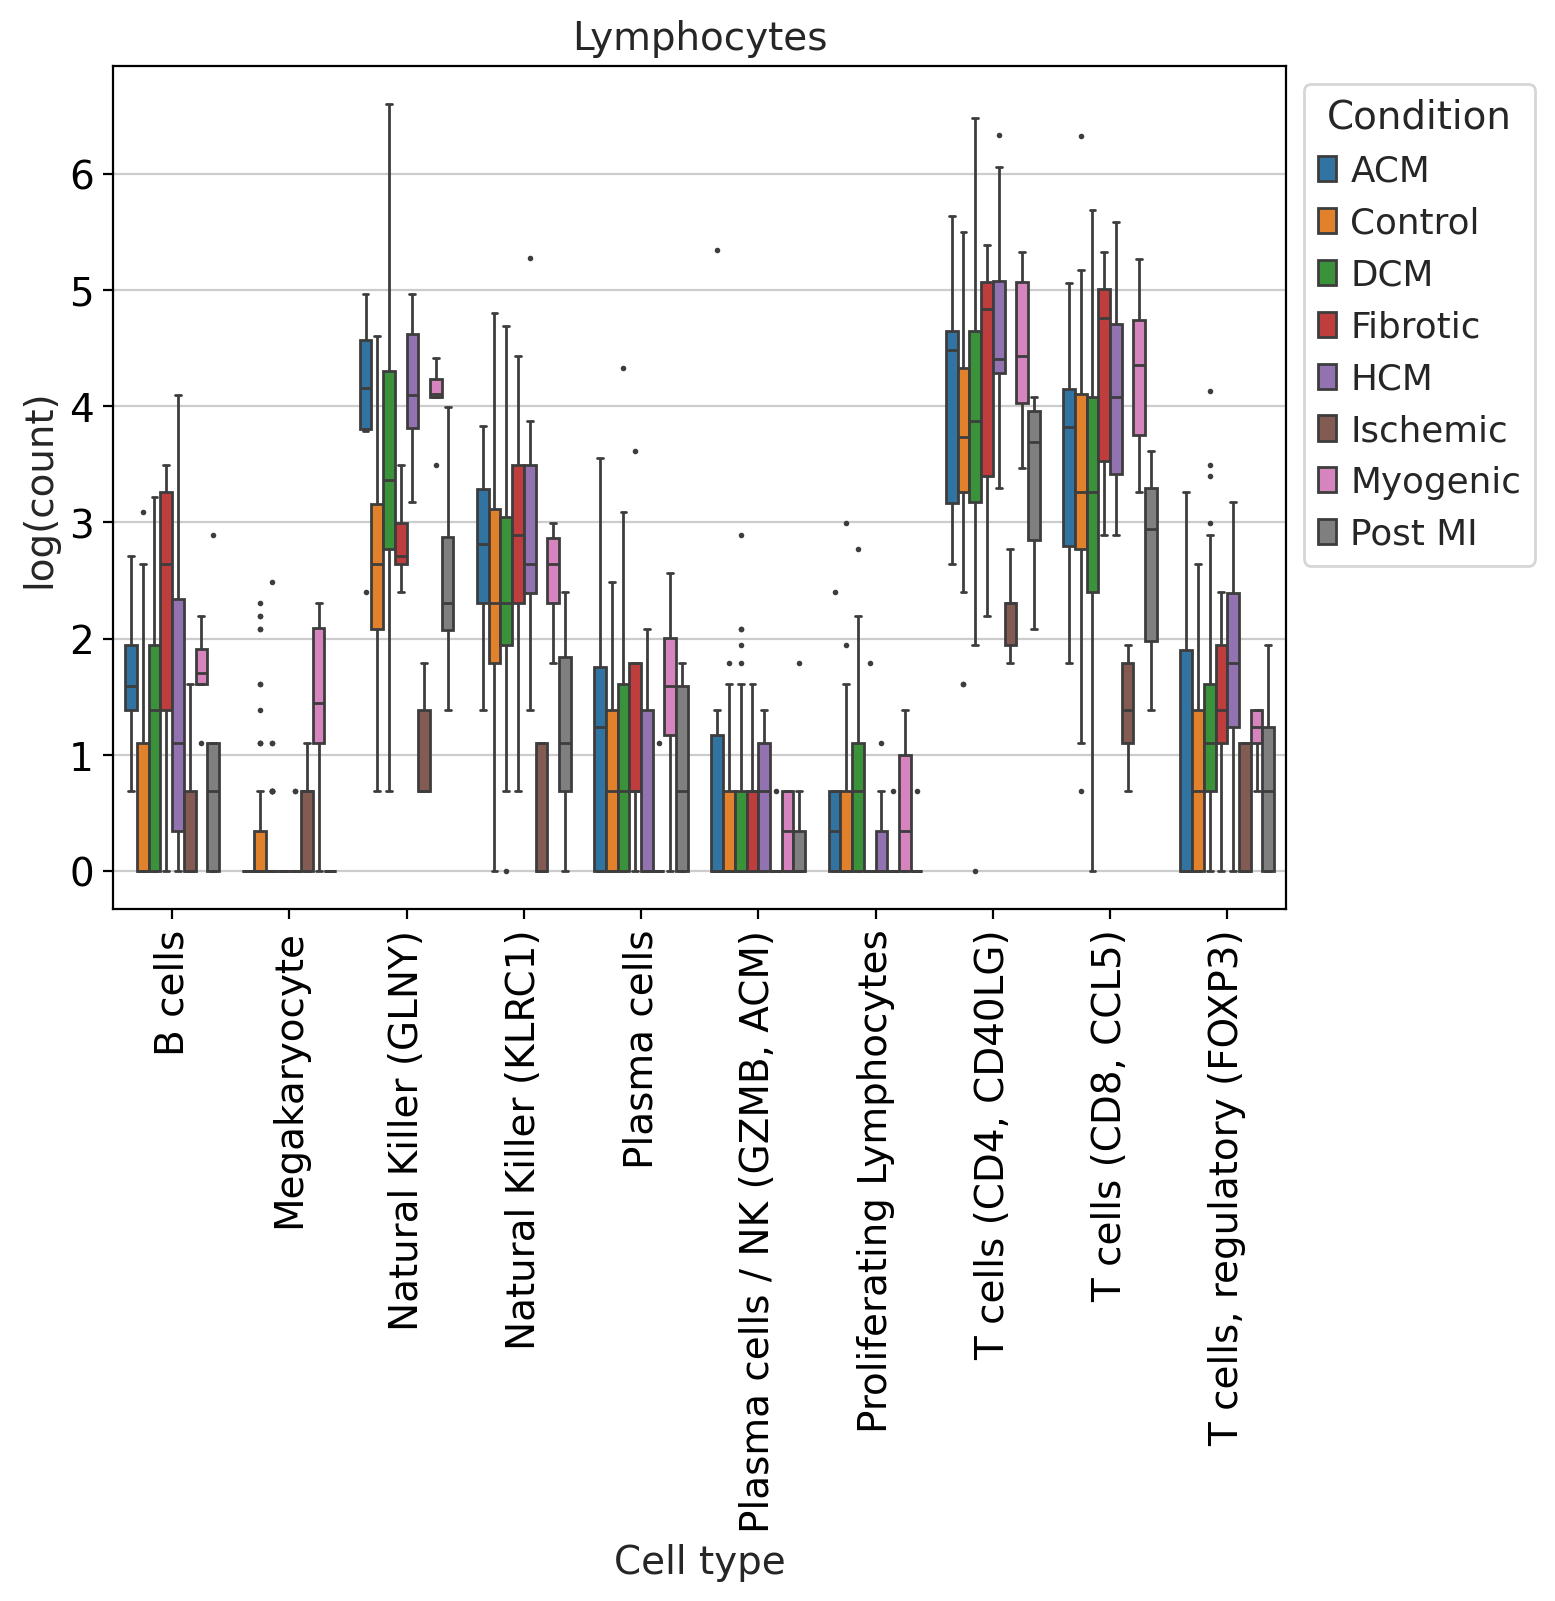

Endothelial


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

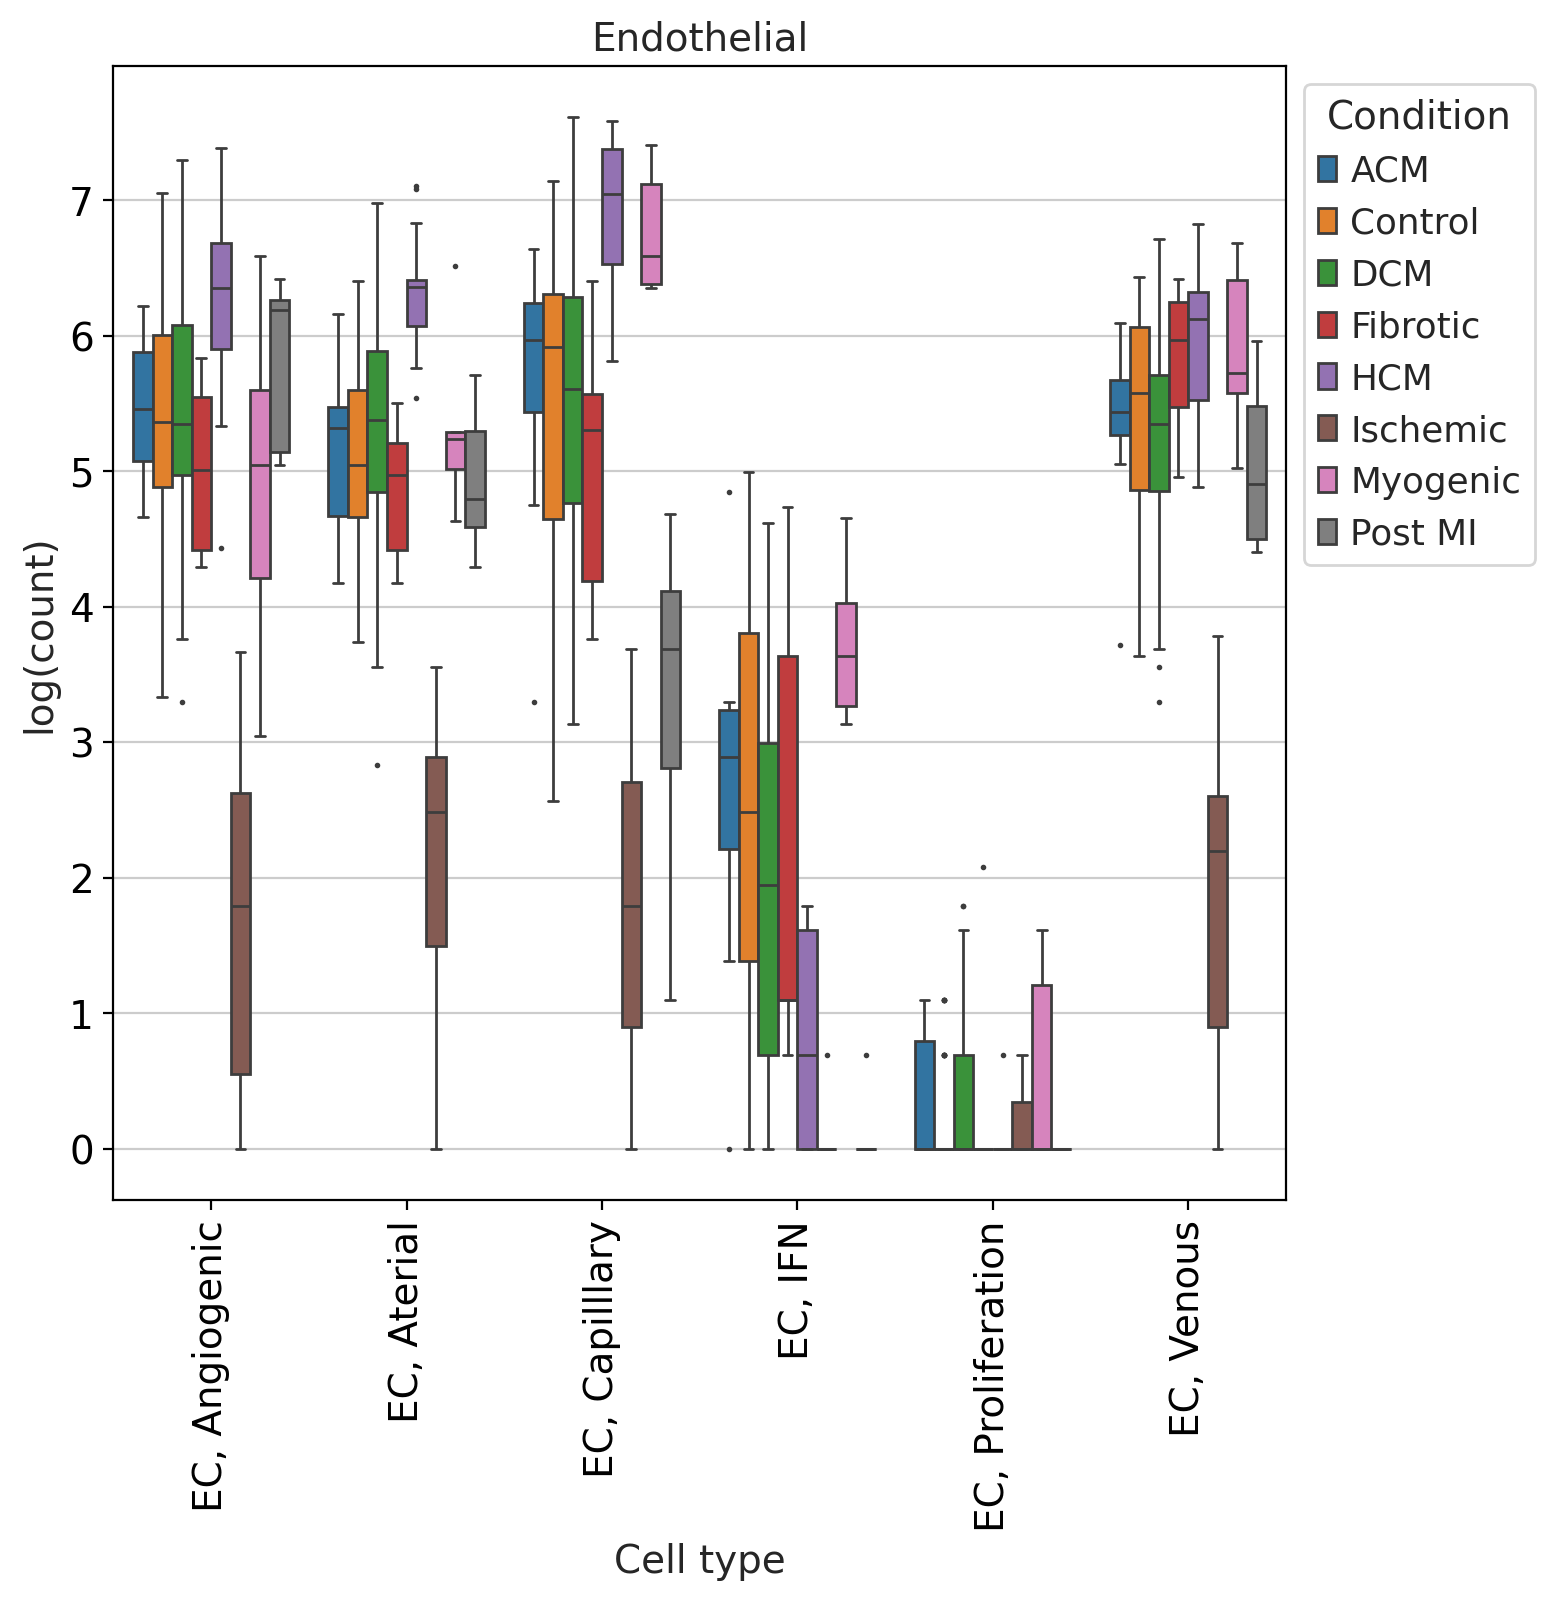

Mast cells


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

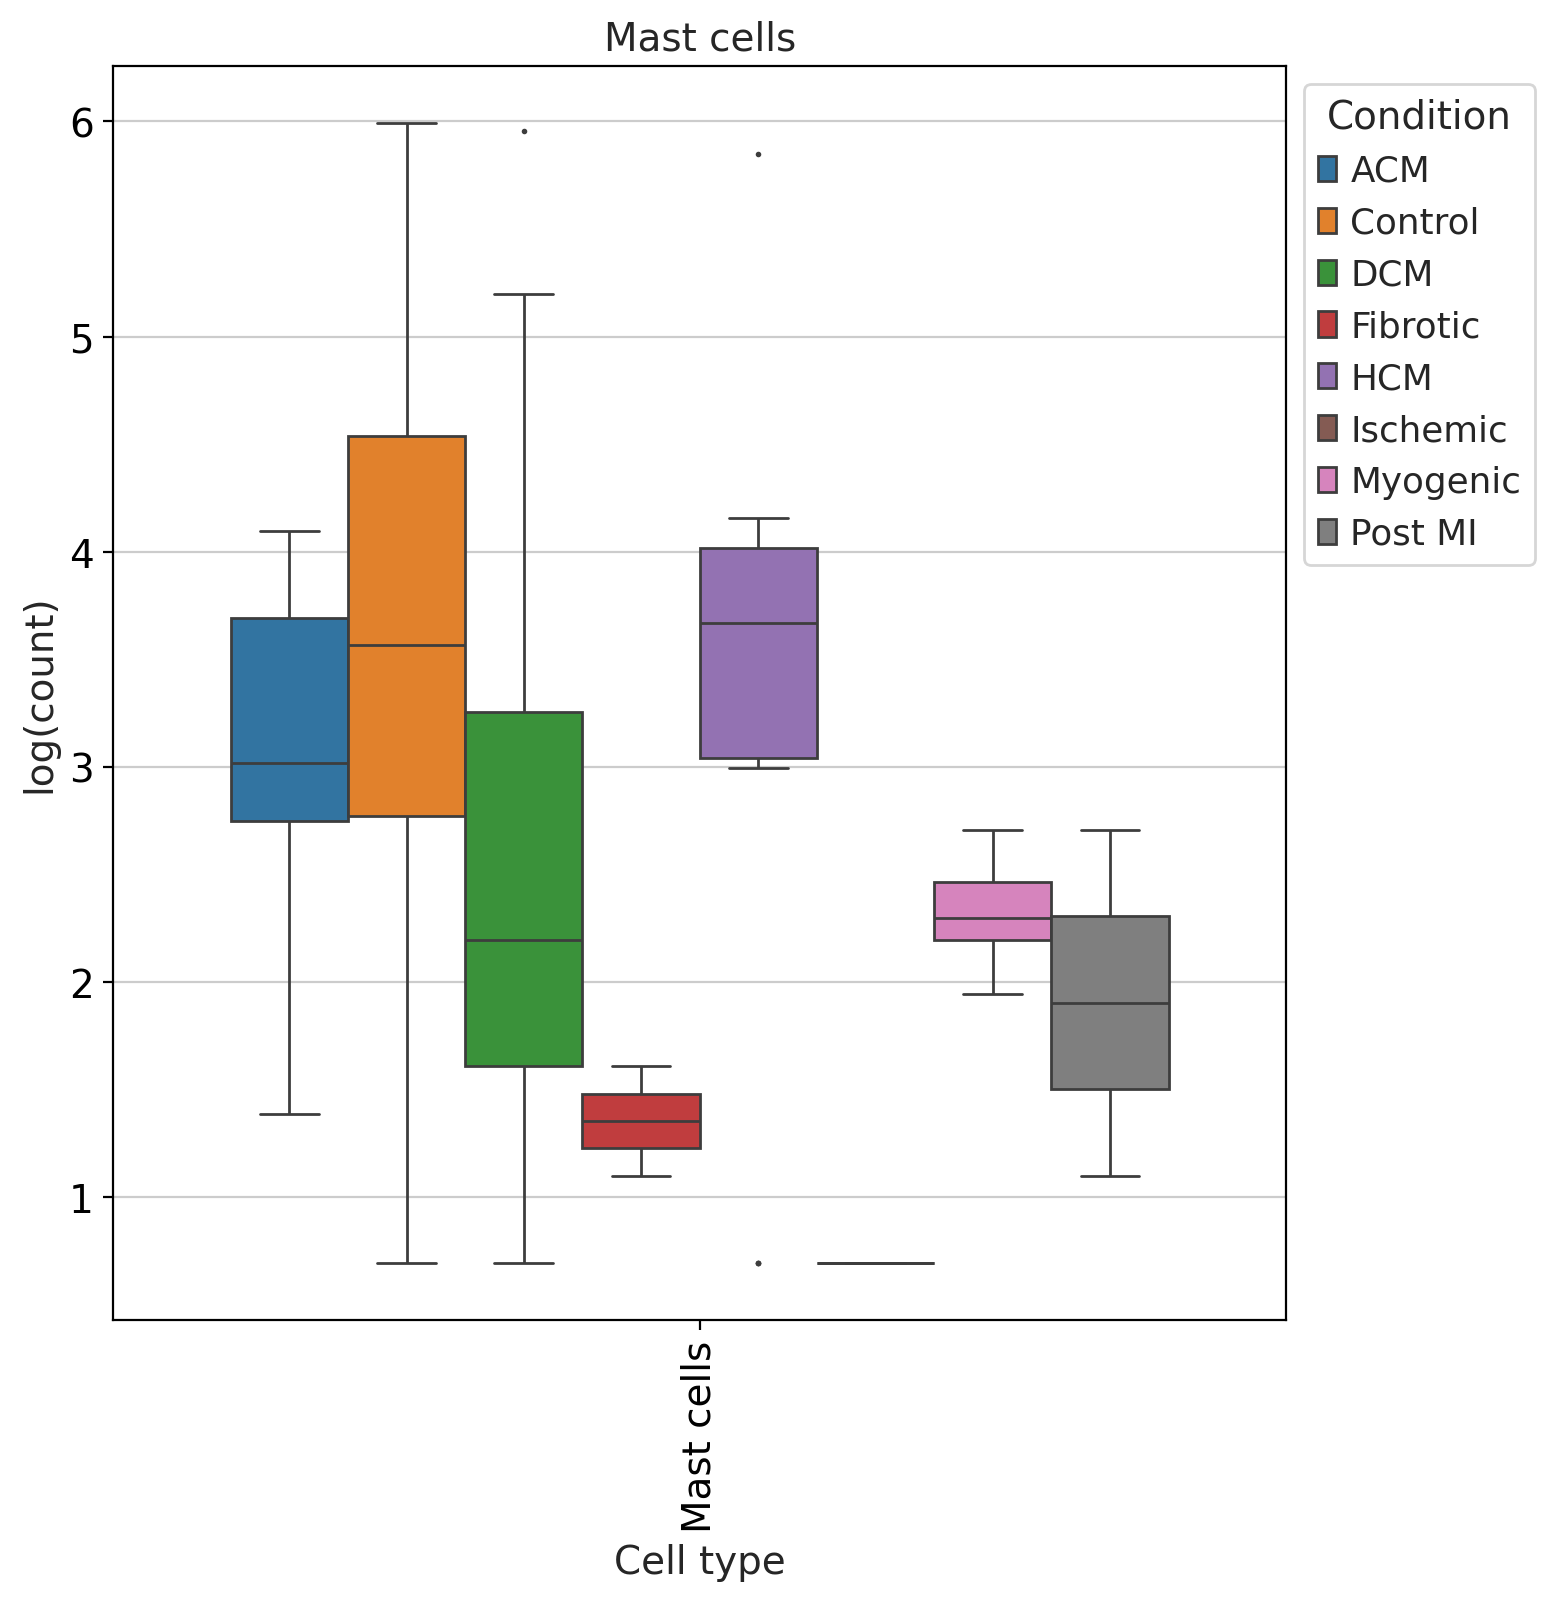

Neuronal


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

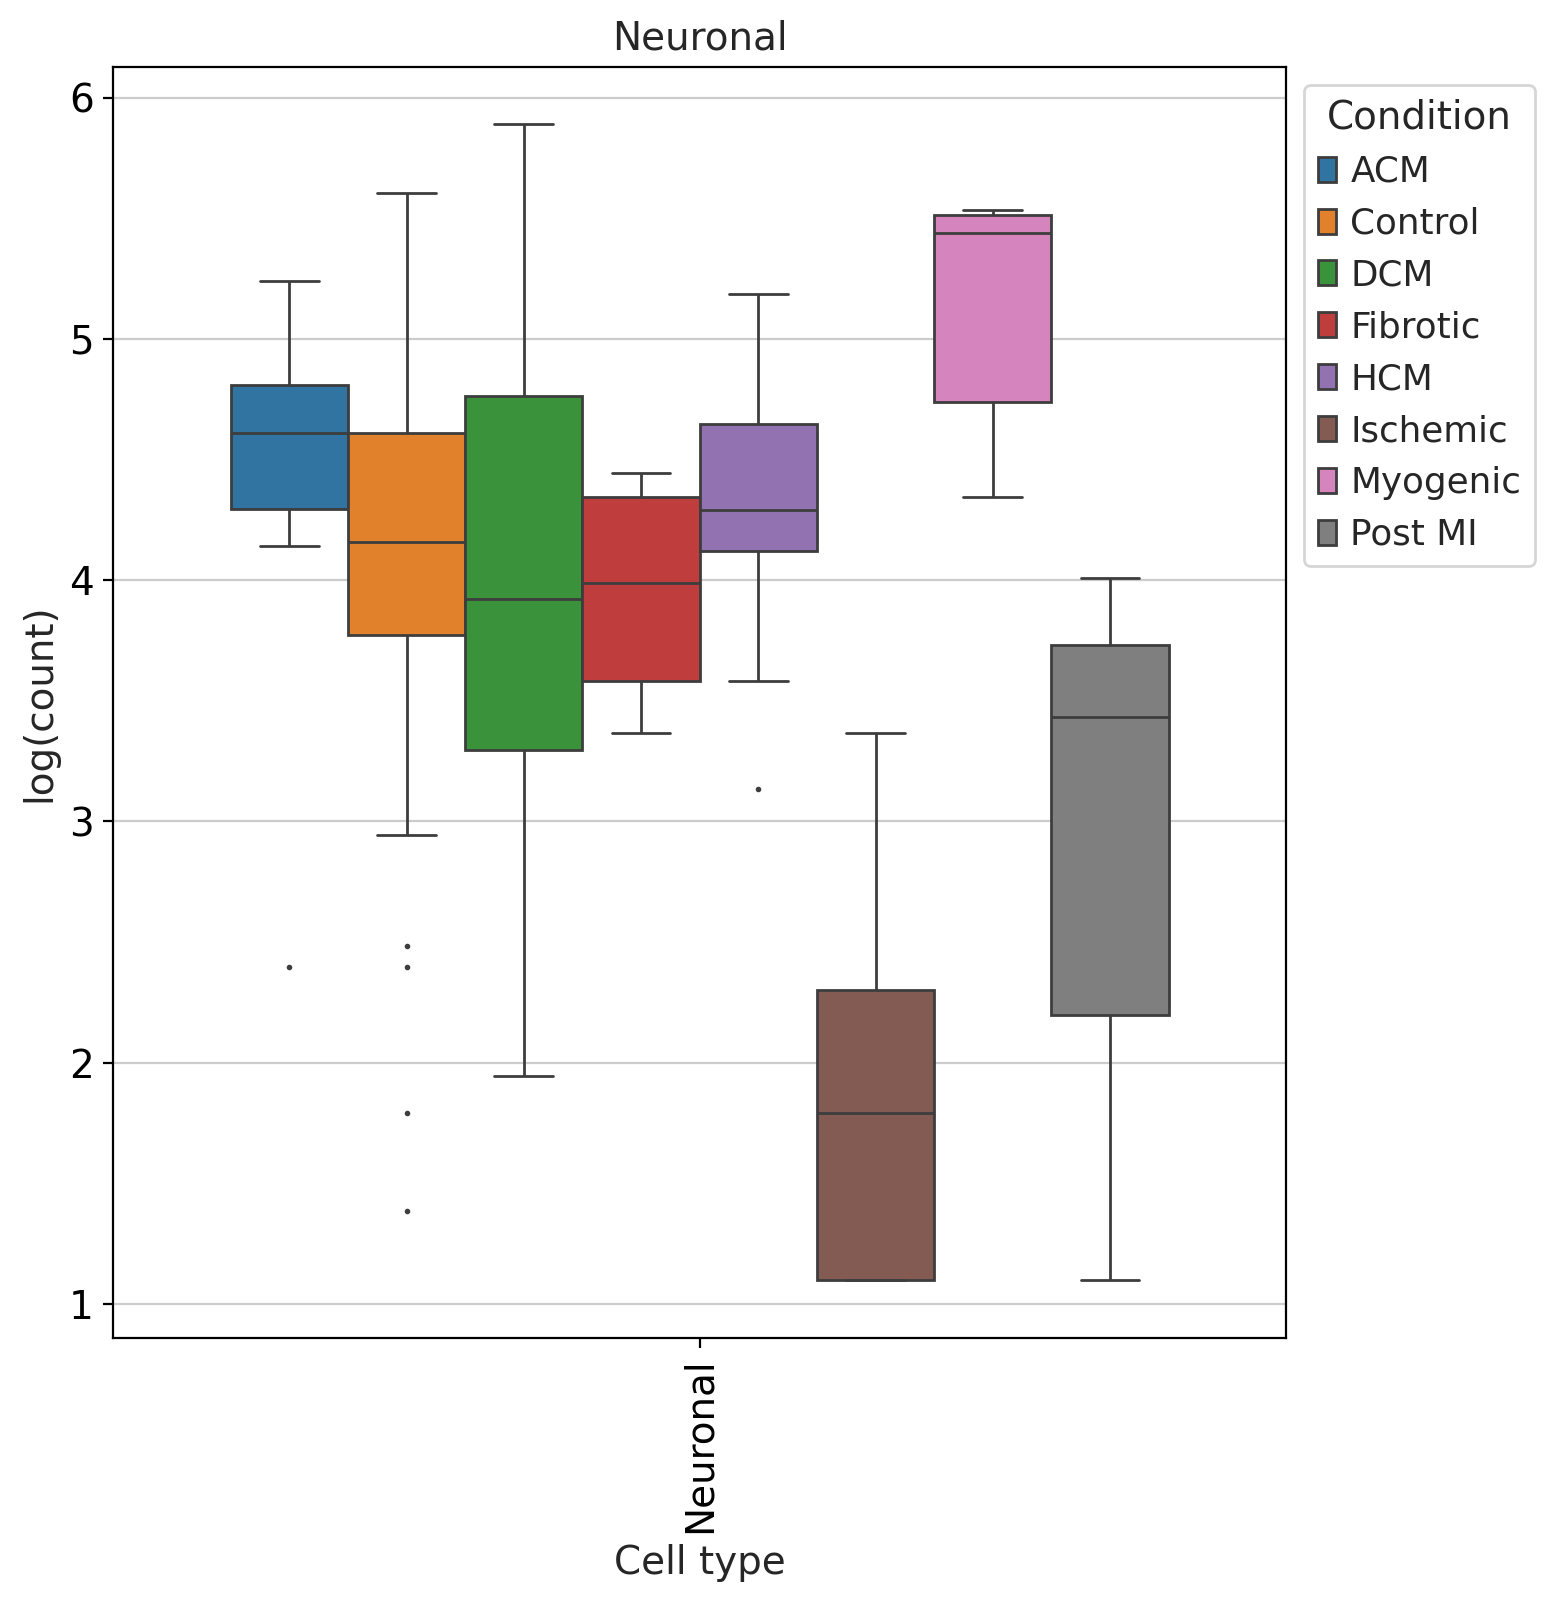

VSMC


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

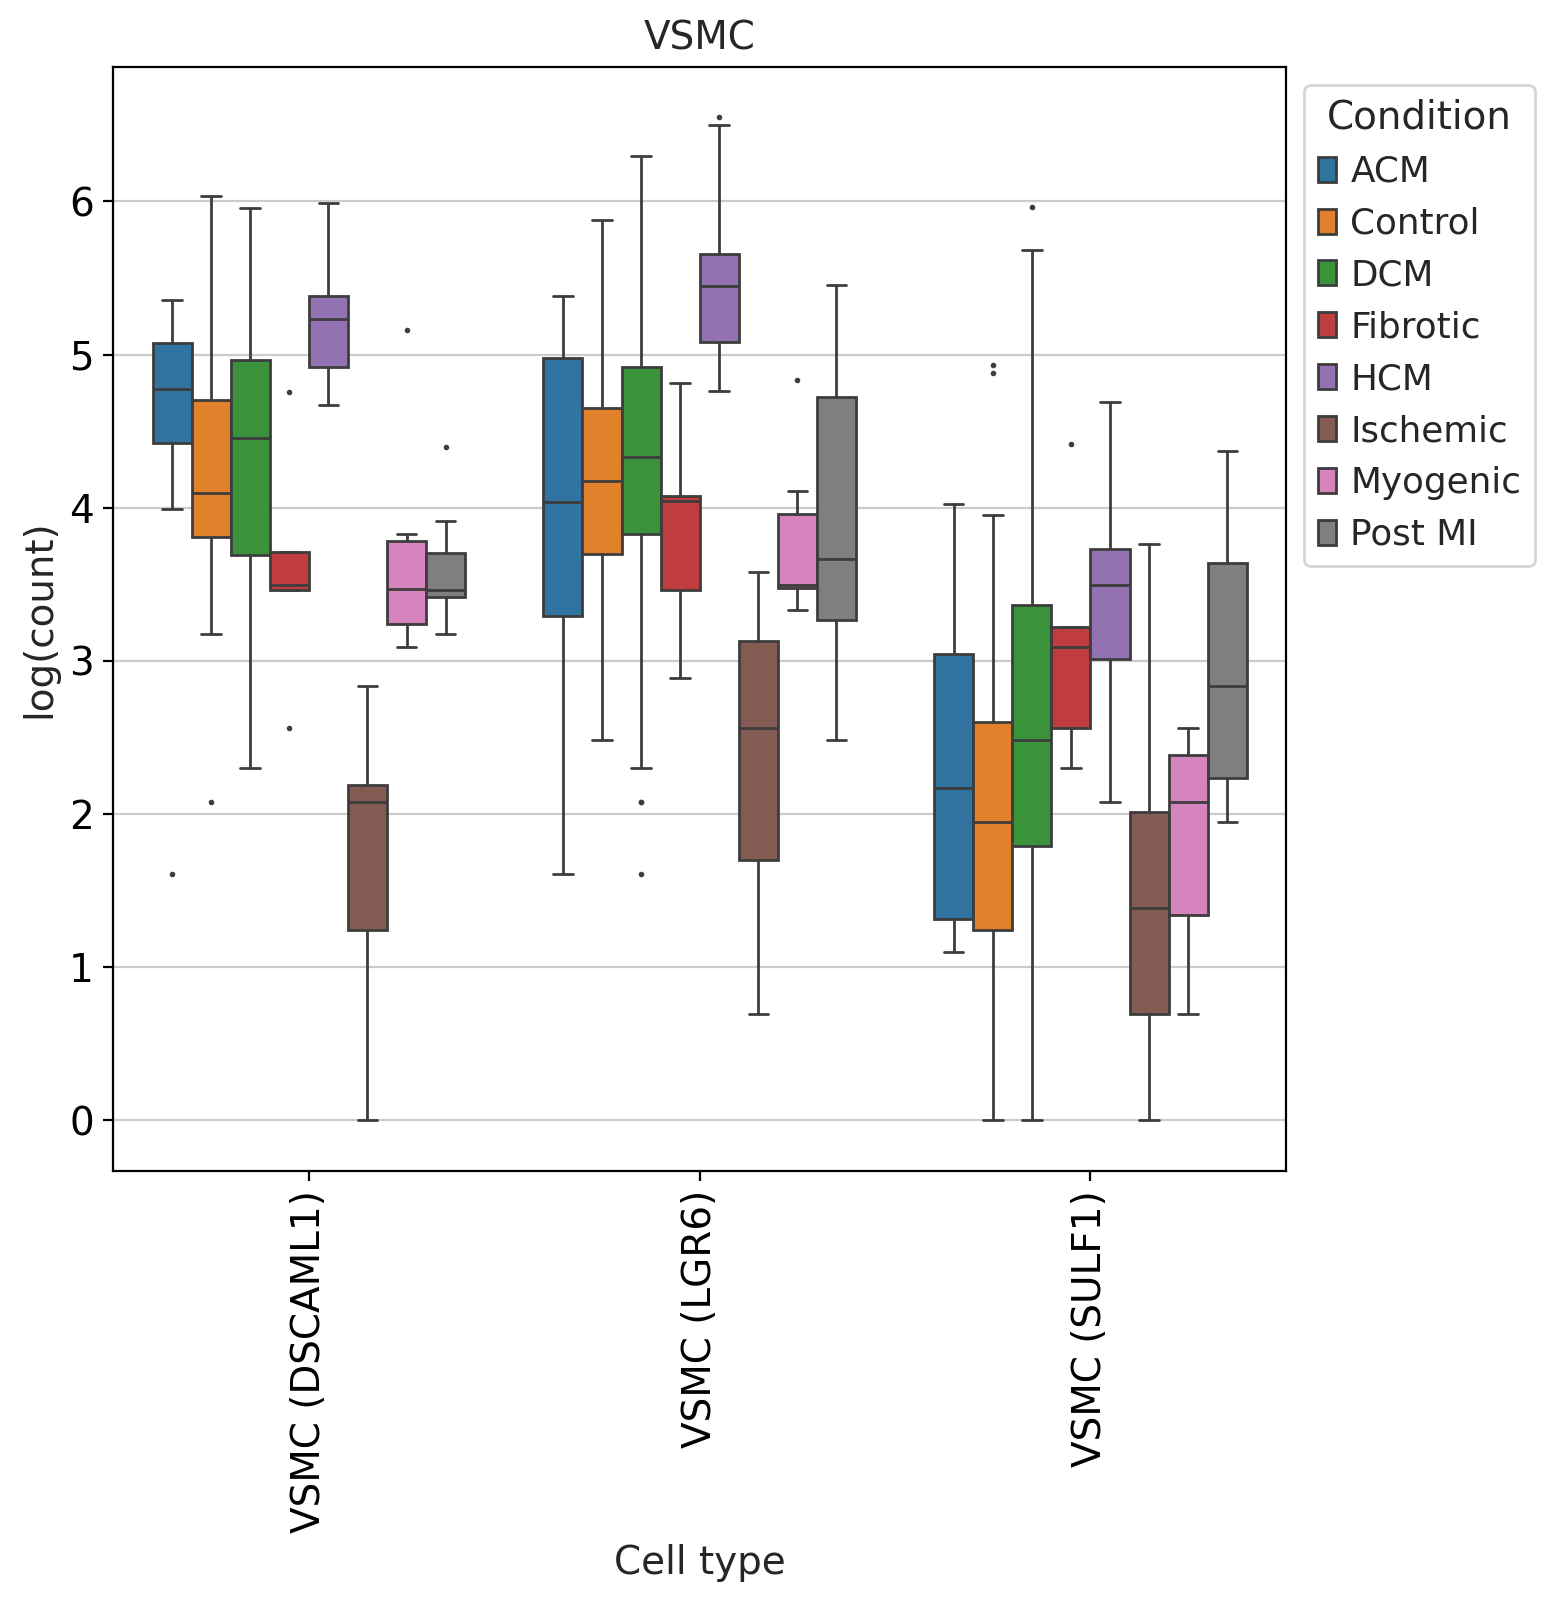

Myeloid


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

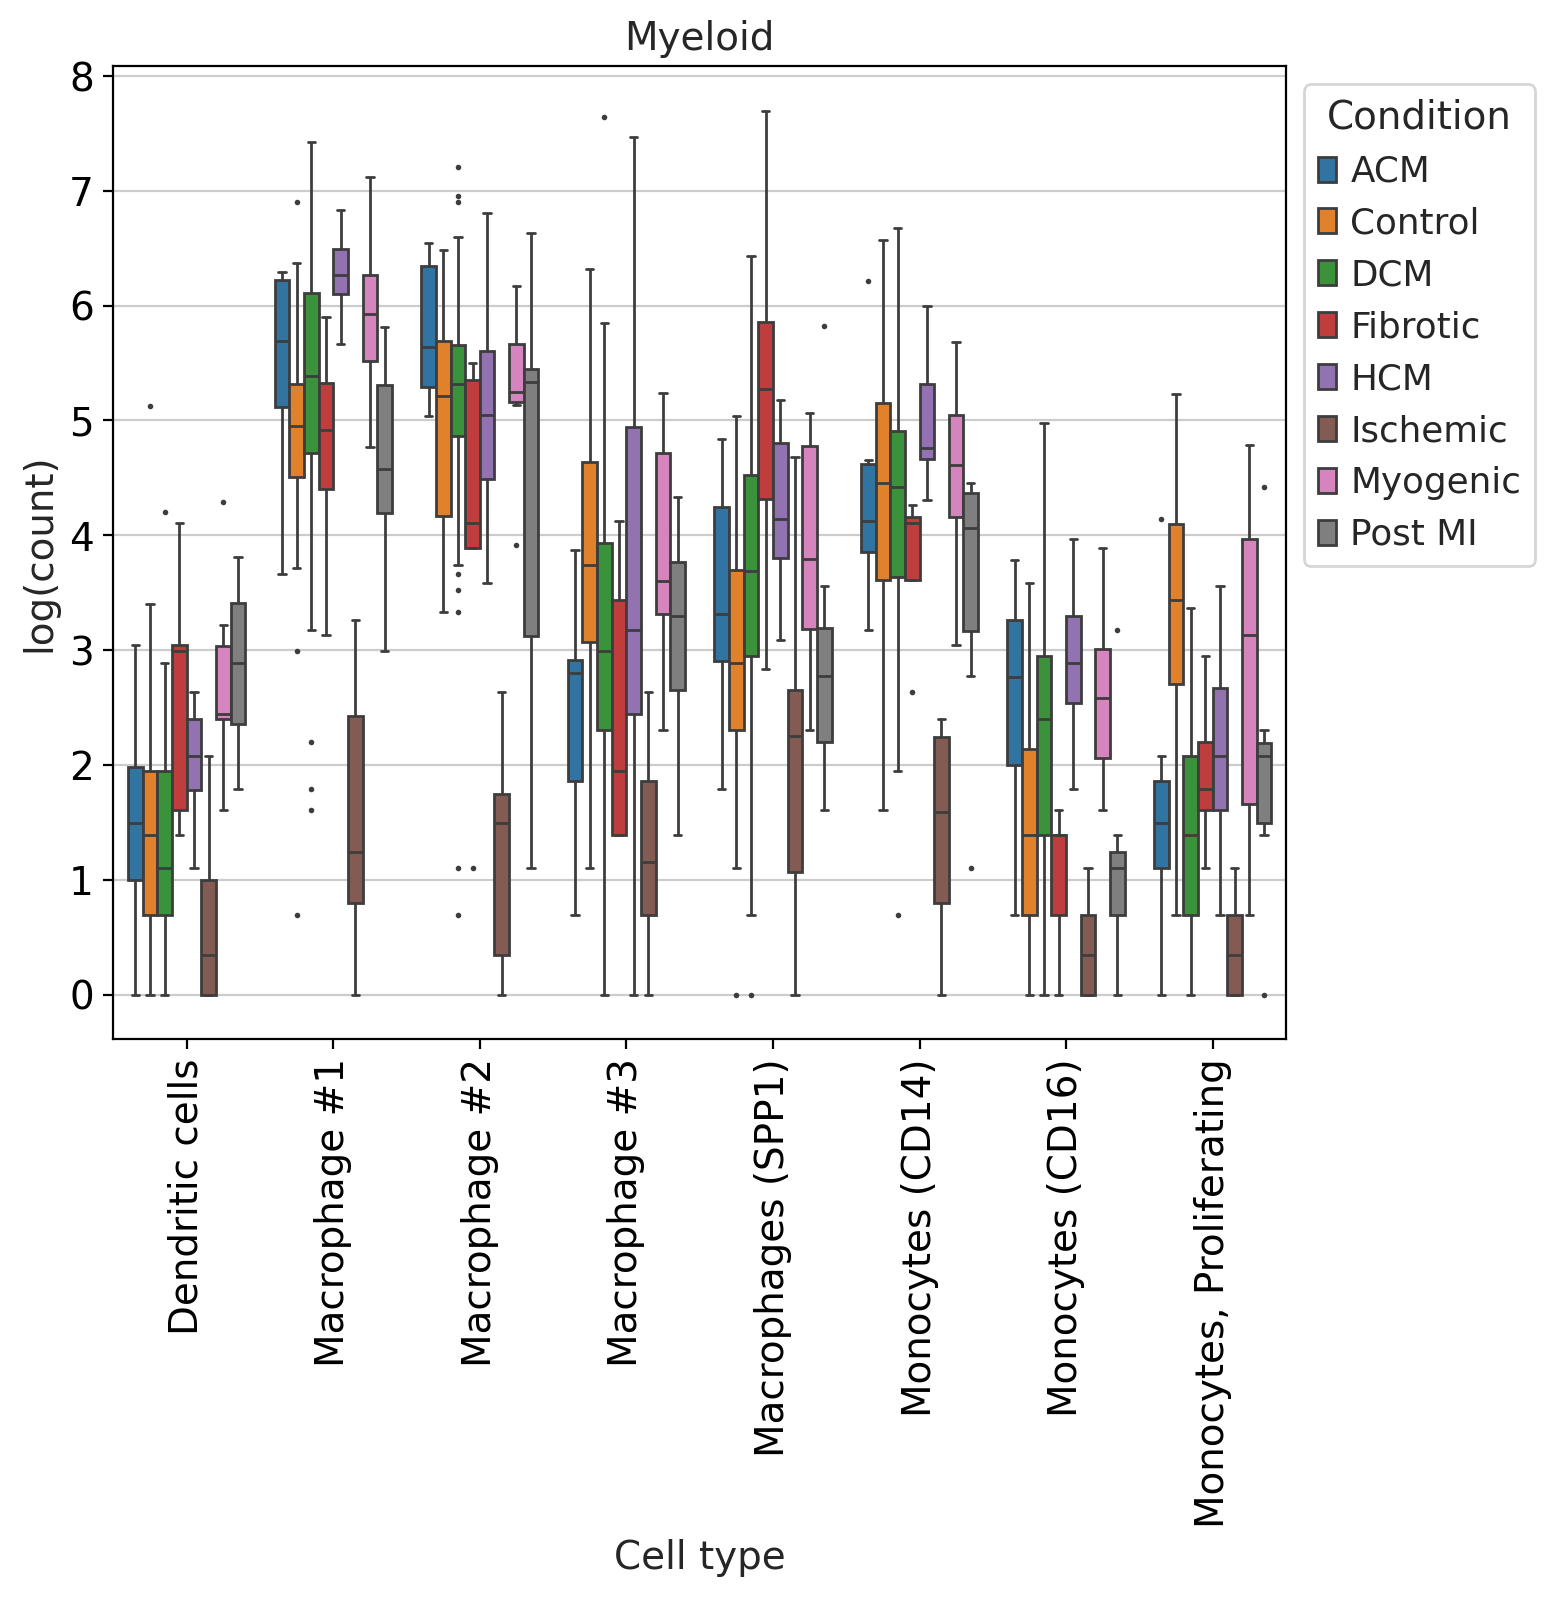

Adipocytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

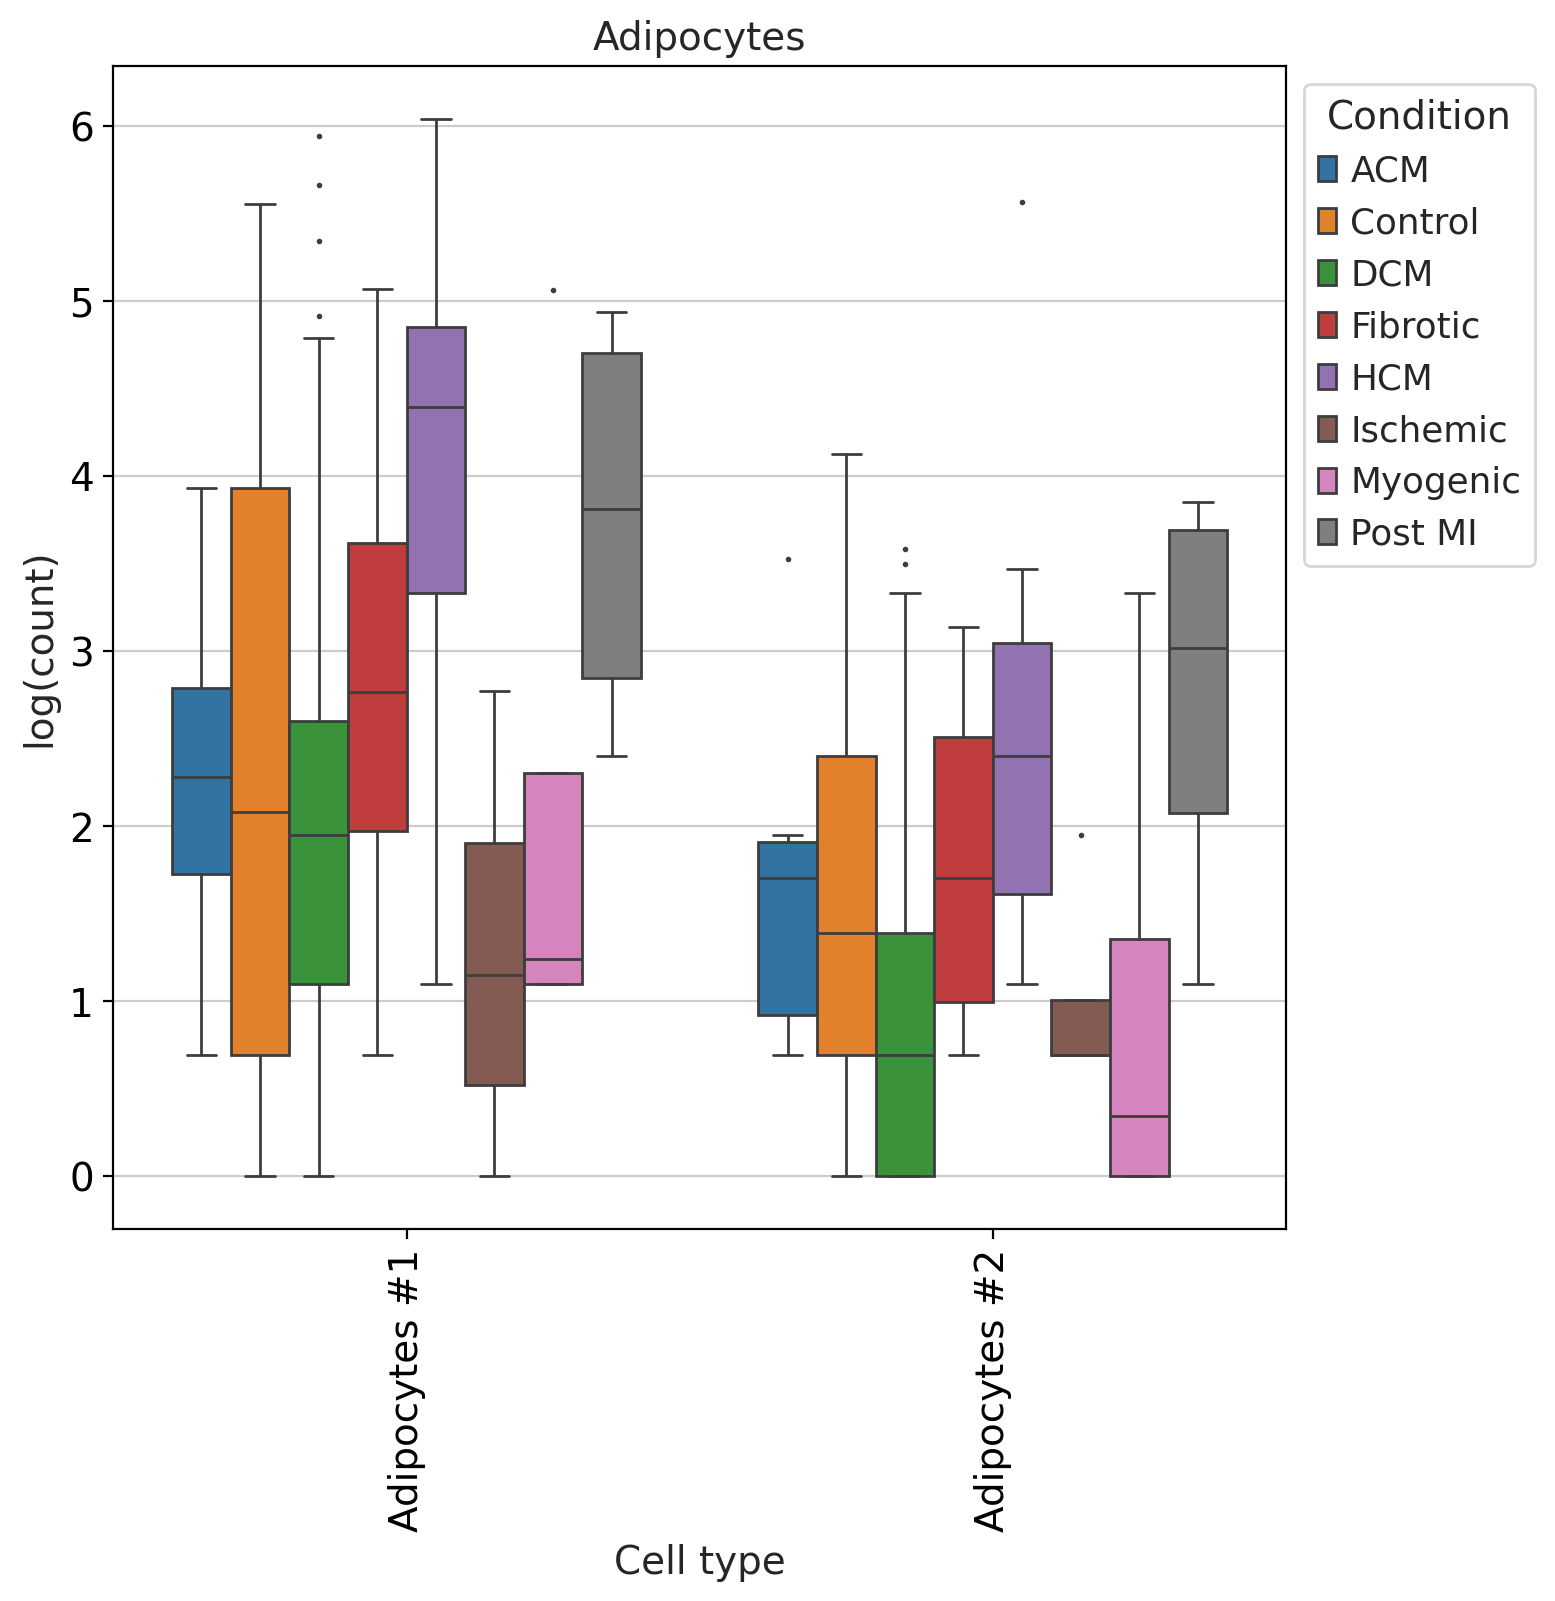

Ischemic cells (MI)


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

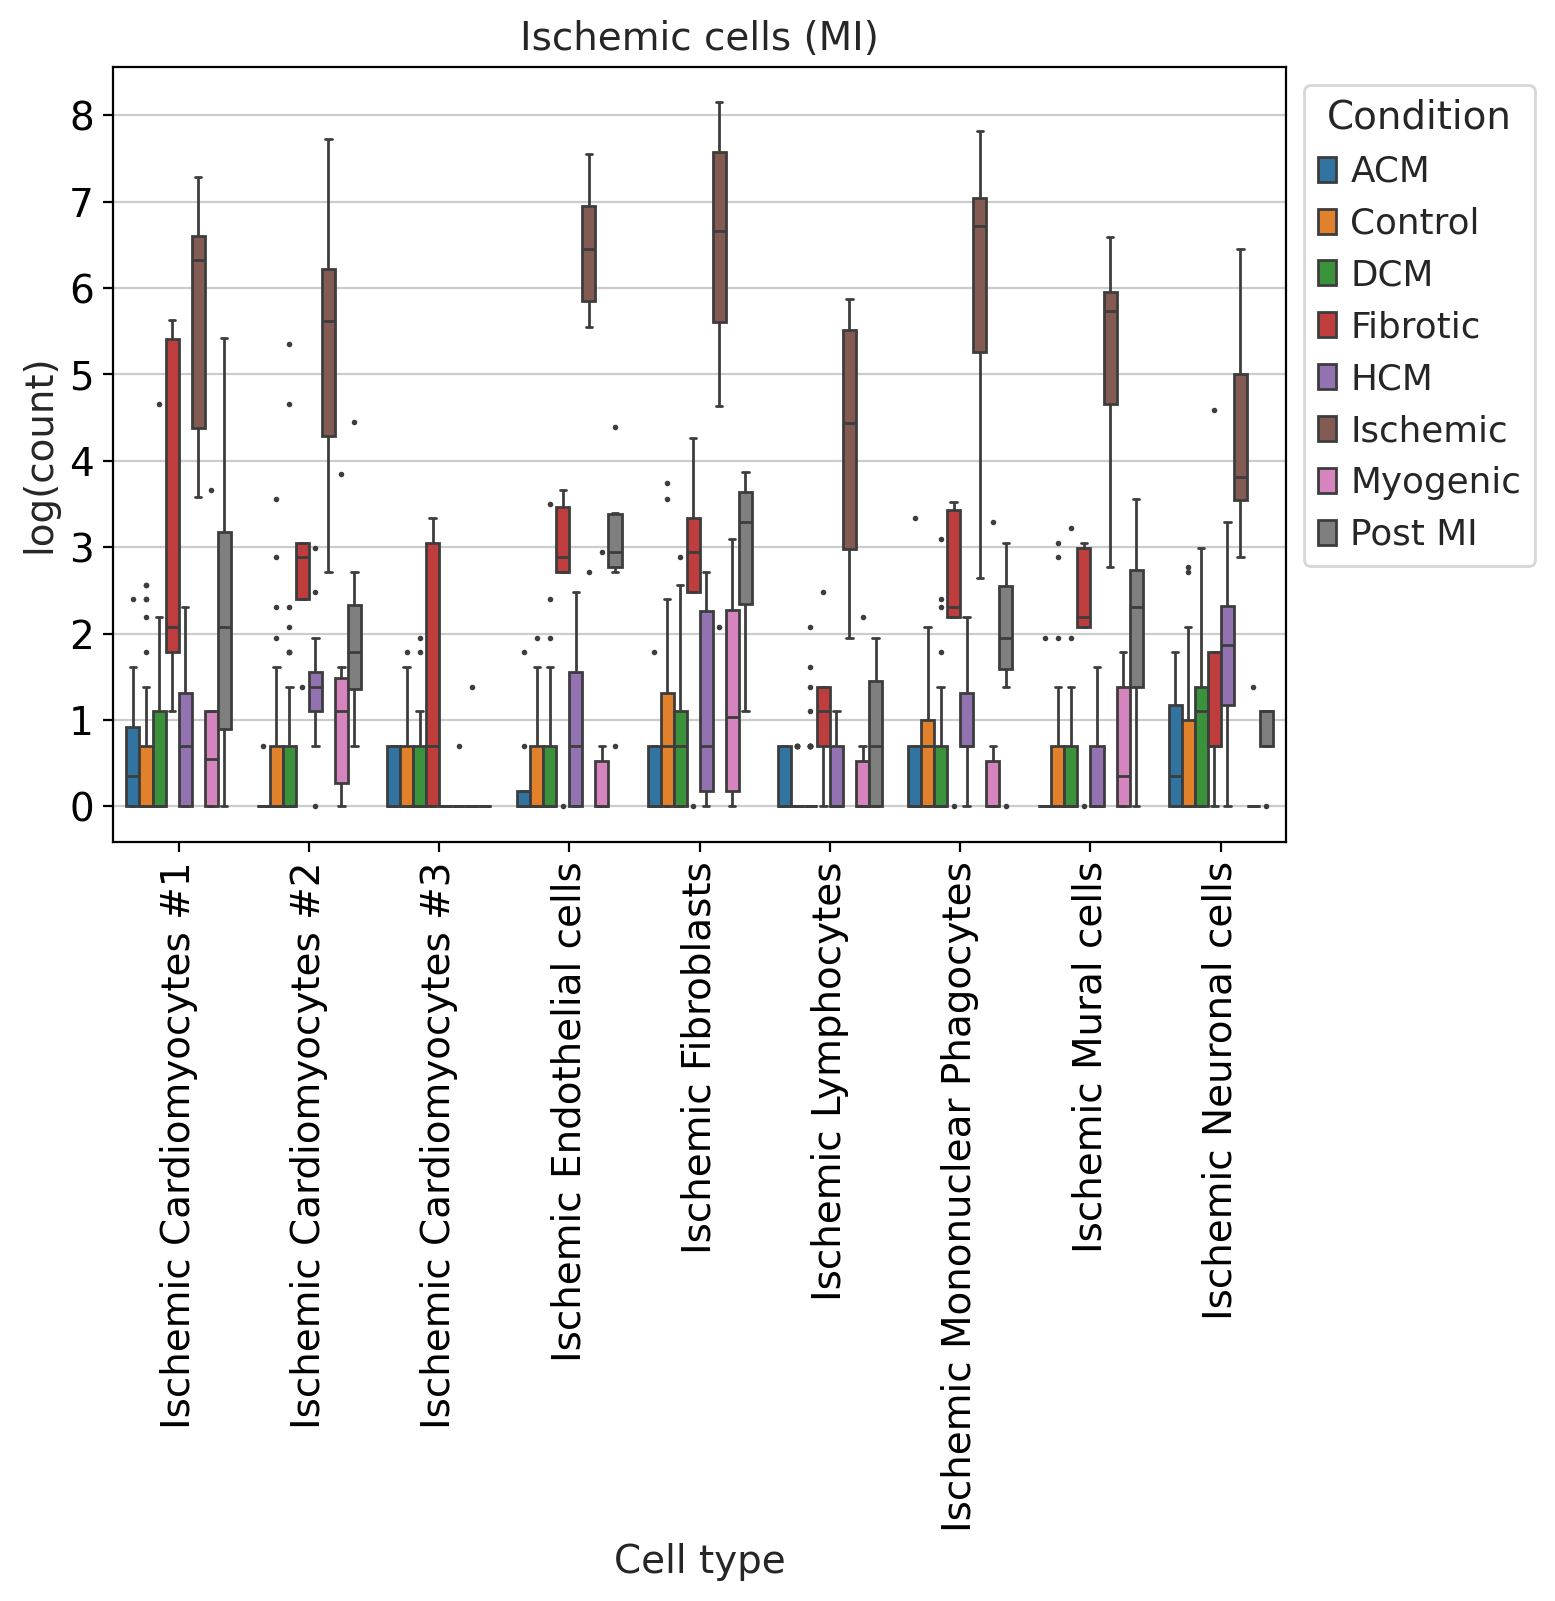

Endocardial


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

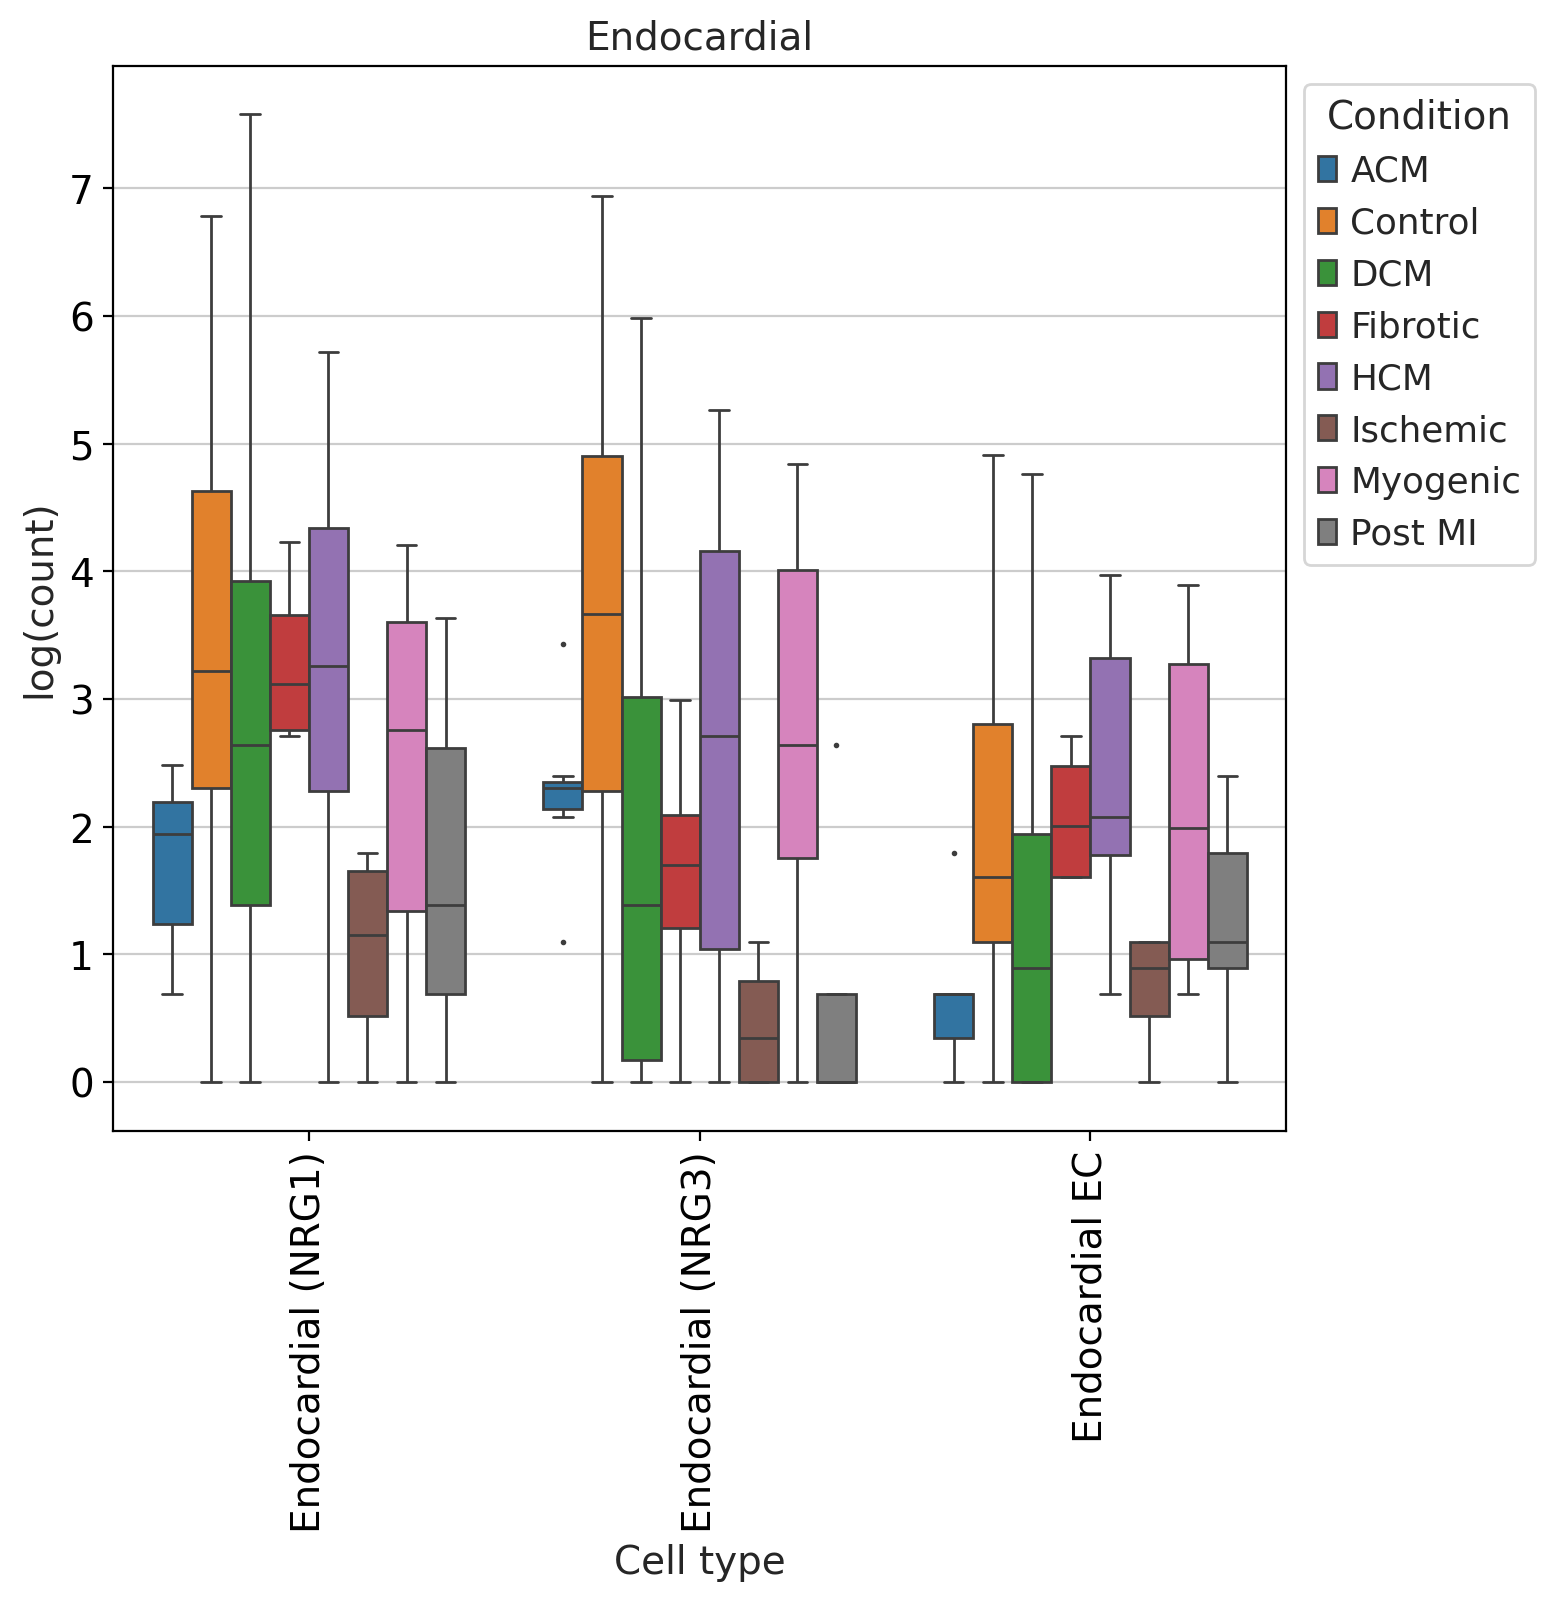

Epicardium


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

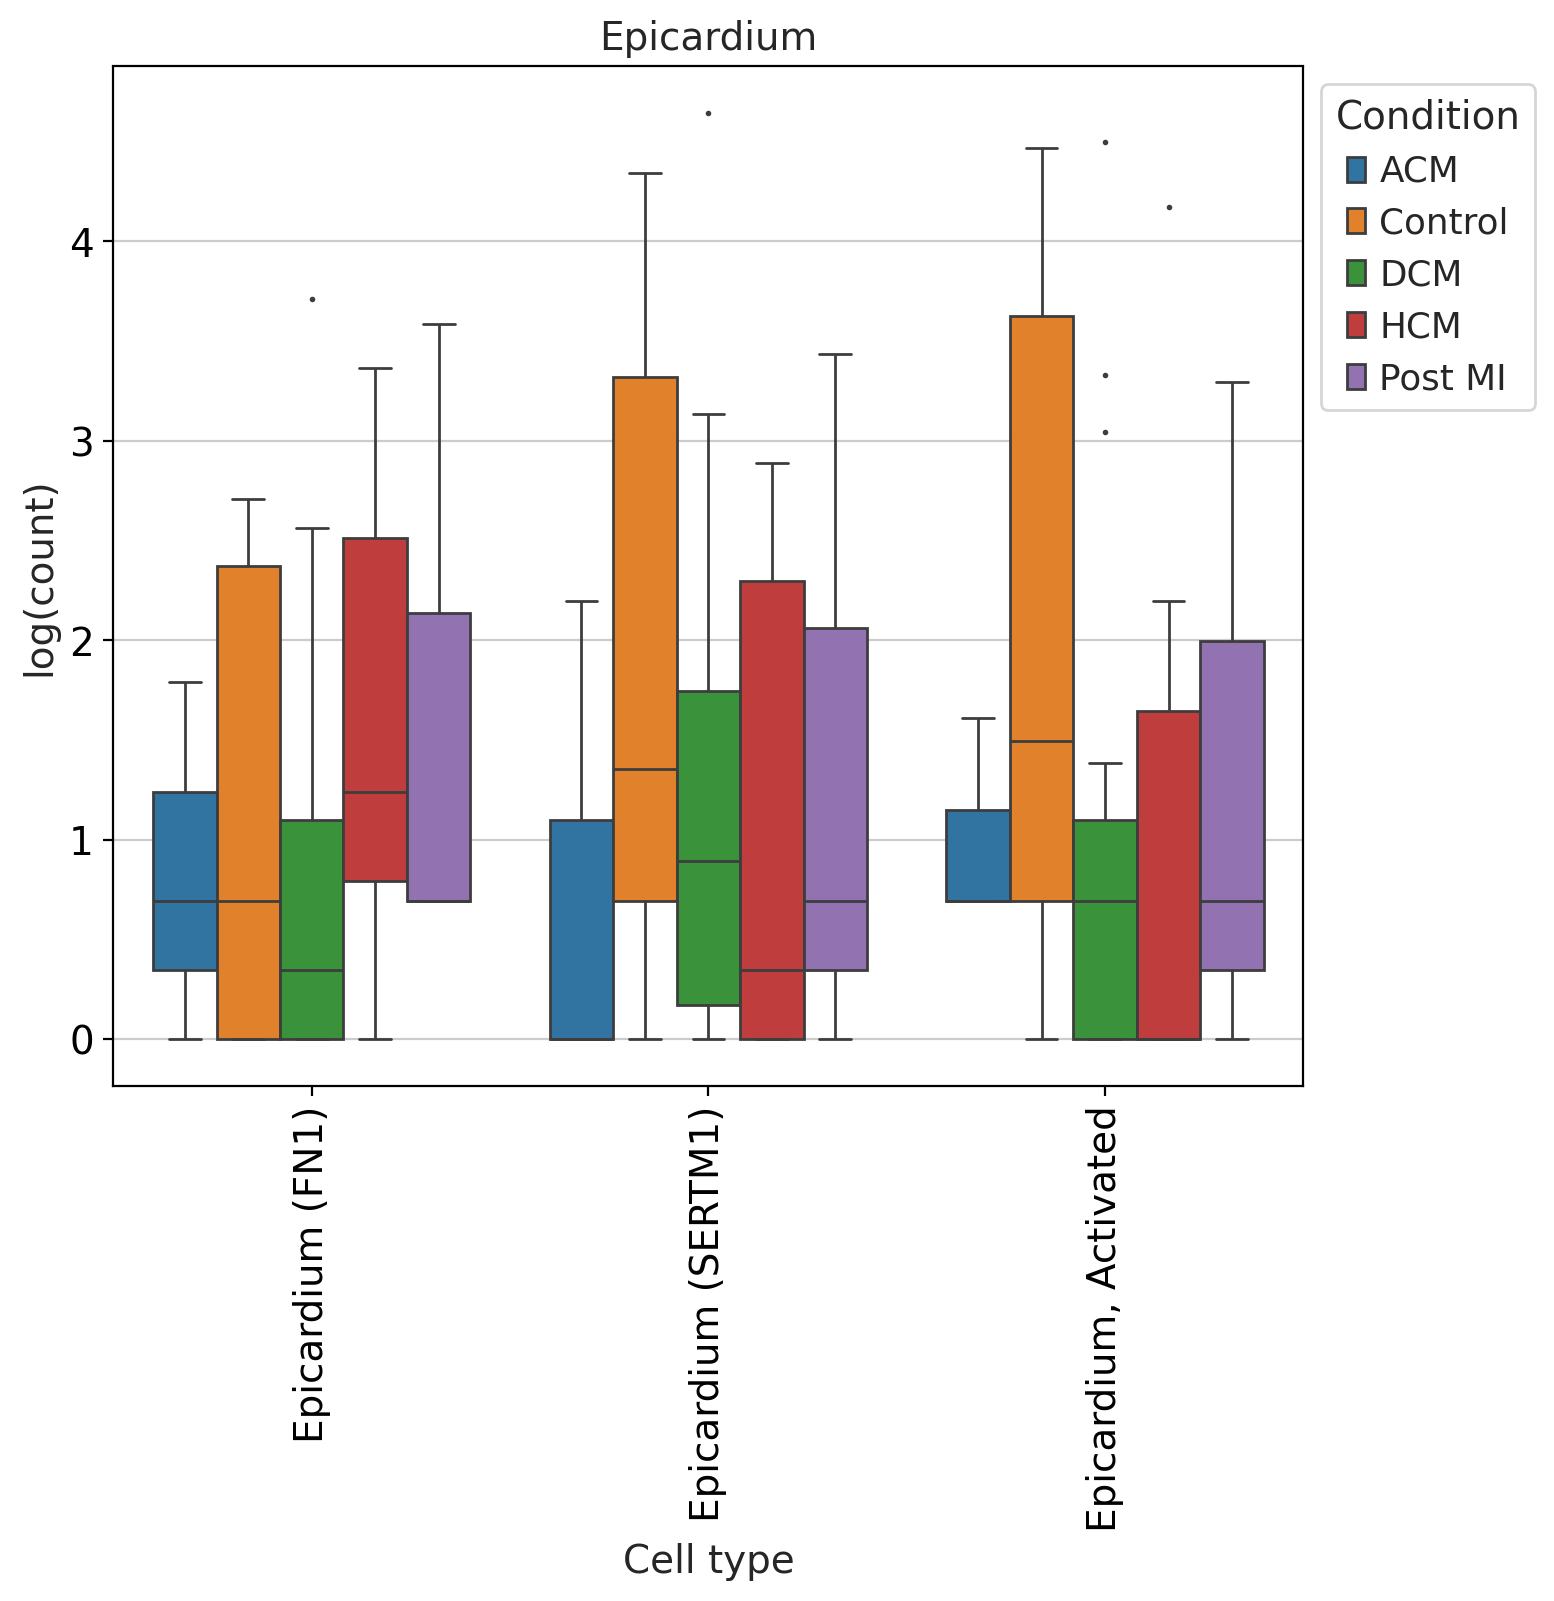

In [8]:
pdf_pages = PdfPages('Boxplot_Subclustering_log_counts.pdf')

for cluster in Heart.obs["Annotation_1"].unique():
    print(cluster)
    plt.figure(figsize=(8, 6))
    subset = Heart[Heart.obs["Annotation_1"].isin([cluster])]
    cross_table = pd.crosstab(index=[subset.obs["Donor"], subset.obs["Condition"]], columns=subset.obs["Subclustering_2"])
    cell_counts = cross_table.reset_index()
    compositions = dat.from_pandas(cell_counts, covariate_columns=["Donor", "Condition"])
    viz.boxplots(compositions,feature_name="Condition",
    plot_facets=False,
    y_scale="log",
    add_dots=False,
    cmap="tab10")
    plt.title(cluster)
    pdf_pages.savefig(plt.gcf(), bbox_inches='tight')
    plt.show()
pdf_pages.close()